# Homework: Neural Networks for Recognition

#### **For each question, please refer to the handout for more details.**

Programming questions begin at **Q2**. **Remember to run all cells** and save the notebook to your local machine as a PDF for gradescope submission.


# Collaborators
**List your collaborators for all questions here**:


---

# Q1 Theory


## Q1.1 (3 points)


Softmax is defined as below, for each index $i$ in a vector $\mathbf{x} \in \mathbb{R}^d$:
$$ \mathop{\text{softmax}}(\mathbf{x})_i = \frac{e^{x_i}}{\sum_j e^{x_j}}. $$
Prove that softmax is invariant to translation; that is,
$$ \mathop{\text{softmax}}(\mathbf{x}) = \mathop{\text{softmax}}(\mathbf{x} + c) \quad \forall c \in \mathbb{R}.$$
Often we use $c = -\max x_i$. Why is that a good idea? *Hint: consider the range of values that the numerator will have with $c=0$ and $c = -\max x_i$.*

---

We may write $\text{softmax}(x+c)$ as $$\mathop{\text{softmax}}(\mathbf{x+c})_i = \frac{e^{(x_i+c)}}{\sum_j e^{(x_j+c)}}=\frac{e^c\cdot e^{x_i}}{e^c\cdot \sum_j e^{x_j}}=\frac{e^{x_i}}{\sum_j e^{x_j}}= \mathop{\text{softmax}}(\mathbf{x})_i$$ Using $c=-\max x_i$ ensures the safety of floating computations and preventions of overflow.

---

## Q1.2

Softmax can be written as a three-step process, with $s_i = e^{x_i}$, $S = \sum s_i$, and $\mathop{\text{softmax}}(\mathbf{x})_i = \frac{1}{S} s_i$.

### Q1.2.1 (1 point)

As $\mathbf{x} \in \mathbb{R}^d$, what are the properties of $\mathop{\text{softmax}}(\mathbf{x})$? Namely, what is the range of each element and what is the sum over all elements?

---

The range of each element is between 0 and 1. The sum over all elements is 1.

---

### Q1.2.2 (1 point)

One could say that *"softmax takes an arbitrary real valued vector $\mathbf{x}$ and turns it into a $\rule{3cm}{0.1mm}$."*

---

probability distribution.

---

### Q1.2.3 (1 point)

Now explain the role of each step in the multistep process.

---

First we exponentiate the arbitrary score by making all the weights positive. Then we sum them up to obtain the total weights. Eventually, we normalize each weight to get their probability distribution.

---

## Q1.3 (3 points)

Show that multi-layer neural networks without a non-linear activation function are equivalent to linear regression.




---

Say that we have a multi-layer network with 1 hidden layer, thus we have $$h_1=W_1^\top x+b_1$$$$y=W_2^\top h_1+b_2$$ Then we plug $h_1$ into $y$, we have $$y=W_2^\top(W_1^\top x+b_1)+b_2=W_2^\top W_1^\top x+(W_2^\top b_1+b_2)$$ which is still equivalent to the linear regression.

---

## Q1.4 (3 points)

Given the sigmoid activation function $\sigma(x) = \frac{1}{1+e^{-x}}$, derive the gradient of the sigmoid function and show that it can be written as a function of $\sigma(x)$ (without having access to $x$ directly).

---

we may derive the gradient as $$\frac {d}{dx}\sigma(x)=\frac {d\sigma (x)}{de^{-x}}\frac {de^{-x}}{dx}=\left(-\frac {1}{(1+e^{-x})^2}\right)\left(-e^{-x}\right)=\frac {e^{-x}}{(1+e^{-x})^2}=\sigma (x)(1-\sigma (x))$$

---

## Q1.5 (12 points)

Given $\mathbf{y} = \mathbf{W}\mathbf{x} + \mathbf{b}$ (or $y_i = \sum_{j=1}^d  x_{j} W_{ij} + b_i$), and the gradient of some loss $J$ (a scalar) with respect to $\mathbf{y}$, show how to get the gradients $\frac{\partial J}{\partial \mathbf{W}}$, $\frac{\partial J}{\partial \mathbf{x}}$ and $\frac{\partial J}{\partial \mathbf{b}}$. Be sure to do the derivatives with scalars and re-form the matrix form afterward. Here are some notational suggestions.
$$ \mathbf{x} \in \mathbb{R}^{d \times 1} \quad \mathbf{y} \in \mathbb{R}^{k \times 1} \quad \mathbf{W} \in \mathbb{R}^{k \times d} \quad \mathbf{b} \in \mathbb{R}^{k \times 1} \quad \frac{\partial J}{\partial \mathbf{y}} = \boldsymbol{\delta} \in \mathbb{R}^{k \times 1} $$

---

The gradients are $$\frac {\partial J}{\partial \textbf W}=\frac {\partial J}{\partial \textbf y}\frac {\partial \textbf y}{\partial \textbf W}=\delta \textbf x^\top$$ $$\frac {\partial J}{\partial \textbf x}=\frac {\partial J}{\partial \textbf y}\frac {\partial \textbf y}{\partial \textbf x}=\textbf W^\top\delta$$ $$\frac {\partial J}{\partial \textbf b}=\frac {\partial J}{\partial \textbf y}\frac {\partial \textbf y}{\partial \textbf b}=\delta$$

---

## Q1.6
When the neural network applies the elementwise activation function (such as sigmoid), the gradient of the activation function scales the backpropagation update. This is directly from the chain rule, $\frac{d}{d x} f(g(x)) = f'(g(x)) g'(x)$.

### Q1.6.1 (1 point)

Consider the sigmoid activation function for deep neural networks. Why might it lead to a "vanishing gradient" problem if it is used for many layers (consider plotting the gradient you derived in Q1.4)?

---

Sigmoid is a function squashed between 0 to 1. For a deep network, if the back propogation goes through many layers, $\sigma (x)(1-\sigma (x))$, a product between 0 and 1, are multiplied for many times, yielding a small number. This is the cause for 'vanishing gradient' problem.

---

### Q1.6.2 (1 point)
Often it is replaced with $\tanh(x) = \frac{1-e^{-2x}}{1+e^{-2x}}$. What are the output ranges of both $\tanh$ and sigmoid? Why might we prefer $\tanh$?

---

$\tanh (x)$ has the output range of $(-1,1)$. $\sigma (x)$ has the output range of $(0,1)$. We prefer $\tanh$ for hidden layers is that it is zero-centered, it may give both positive and negative output, which makes the gradient updates more balanced.

---

### Q1.6.3 (1 point)
Why does $\tanh(x)$ have less of a vanishing gradient problem? (Plotting the gradients helps! For reference: $\tanh'(x) = 1 - \tanh(x)^2$.)

---

$\tanh(x)$ has less of a vanishing-gradient problem than sigmoid because its derivative can be as large as 1 near x=0, whereas the sigmoid derivative is at most 1/4, so gradients shrink less during backpropagation.

---

### Q1.6.4 (1 point)
$\tanh$ is a scaled and shifted version of the sigmoid. Show how $\tanh(x)$ can be written in terms of $\sigma(x)$.

---

We may write $\tanh$ as $$\tanh (x)=\frac {2}{1+e^{-2x}}-1=2\sigma (2x)-1$$

---


# Q2 Implement a Fully Connected Network

Run the following code to import the modules you'll need. When implementing the functions in Q2, make sure you run the test code (provided after Q2.3) along the way to check if your implemented functions work as expected.

In [2]:
import os
import pickle
import string
from collections.abc import Callable, Sequence
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import scipy.io
from mpl_toolkits.axes_grid1 import ImageGrid

In [3]:
# ============ PROVIDED CODE: small plotting helpers used throughout ============
# NIST36 class order: the 26 upper-case letters, then the 10 digits.
CLASSES: str = string.ascii_uppercase + string.digits


def show_image_grid(
    images: Sequence[np.ndarray] | np.ndarray,
    nrows_ncols: tuple[int, int],
    title: str | None = None,
    figsize: tuple[float, float] | None = None,
    **imshow_kwargs: Any,
) -> None:
    """Display flattened 32x32 images (rows of an array, or a list) in a grid."""
    fig = plt.figure(figsize=figsize)
    if title is not None:
        plt.title(title)
    plt.axis("off")
    grid = ImageGrid(fig, 111, nrows_ncols=nrows_ncols, axes_pad=0.05)
    for ax, image in zip(grid, images):  # type: ignore
        ax.imshow(np.asarray(image).reshape(32, 32).T, **imshow_kwargs)
        ax.set_axis_off()
    plt.show()


def plot_curves(curves: dict[str, list[float]], ylabel: str) -> None:
    """Plot one or more curves, given as a mapping of label to per-epoch values."""
    for label, values in curves.items():
        plt.plot(range(len(values)), values, label=label)
    plt.xlabel("epoch")
    plt.ylabel(ylabel)
    plt.xlim(0, max(len(v) for v in curves.values()) - 1)
    plt.ylim(0, None)
    if len(curves) > 1:
        plt.legend()
    plt.grid()
    plt.show()

## Q2.1 Network Initialization

### Q2.1.1 (3 points)

Why is it not a good idea to initialize a network with all zeros? If you imagine that every layer has weights and biases, what can a zero-initialized network output be after training?

---

If we initialize the weight and biases to be 0, then the forward and backward propogation during training does not make anything different. For every layer, every neuron starts at the same state and it receives the same gradients. Gradient cannot make anything different.

---

### Q2.1.2 (3 points)

Implement the `initialize_weights()` function to initialize the weights for a single layer with Xavier initialization [Glorot et al.], where $\mathop{\text{Var}}[w] = \frac{2}{n_\text{in}+ n_\text{out}}$ where $n$ is the dimensionality of the vectors and you use a **uniform distribution** to sample random numbers (see Eq. 16 in [Glorot et al.]).

In [4]:
############################## Q 2.1.2 ##############################
rng = np.random.default_rng(seed=0)  # you can use this rng to sample random numbers


def initialize_weights(
    in_size: int, out_size: int, params: dict[str, Any], name: str = ""
) -> None:
    """
    We will do XW + b, with the size of the input data array X being [number of examples, in_size].
    The weights W should be initialized as a 2D array.
    The bias vector b should be initialized as a 1D array, not a 2D array with a singleton dimension.
    The output of this layer should have size [number of examples, out_size].
    """

    limit = np.sqrt(6 / (in_size + out_size))
    W = rng.uniform(-limit, limit, size=(in_size, out_size))
    b = np.zeros(out_size,) # Biases typically initialized to zeros

    params[f"W{name}"] = W
    params[f"b{name}"] = b

### Q2.1.3 (2 points)

Why do we scale the initialization depending on layer size (see Fig. 6 in [Glorot et al.])?

---

That keeps both activations and gradients from vanishing or exploding.

---

## Q2.2 Forward Propagation

The Appendix (Sec. 8 of the handout) has the math for forward propagation. We will implement it here.

### Q2.2.1 (4 points)

Implement the `sigmoid()` function, which computes the elementwise sigmoid activation of entries in an input array. Then implement the `forward()` function which computes forward propagation for **a single layer**, namely $\mathbf{y} = \sigma(\mathbf{X}\mathbf{W} + \mathbf{b})$.

In [5]:
############################## Q 2.2.1 ##############################
def sigmoid(x: np.ndarray) -> np.ndarray:
    """
    Implement an elementwise sigmoid activation function on the input x,
    where x is a numpy array of size [number of examples, number of output dimensions].
    """
    sigmoid_x = np.array([])
    sigmoid_x = 1 / (1 + np.exp(-x))
    return sigmoid_x

In [6]:
############################## Q 2.2.1 ##############################
def forward(
    X: np.ndarray,
    params: dict[str, Any],
    name: str = "",
    activation: Callable[[np.ndarray], np.ndarray] = sigmoid,
) -> np.ndarray:
    """
    Do a forward pass for a single layer that computes the output: activation(XW + b).

    Args:
        X: input numpy array of size [number of examples, number of input dimensions]
        params: a dictionary containing parameters, as you initialized in Q 2.1.2
        name: name of the layer
        activation: the activation function (default is sigmoid)
    """
    # get the layer parameters
    W = params["W" + name]
    b = params["b" + name]

    # compute the output values before and after the activation function
    pre_act, post_act = np.array([]), np.array([])
    pre_act=X@W+b
    post_act=activation(pre_act)

    # store the pre-activation and post-activation values
    # these will be important in backpropagation
    params["cache_" + name] = (X, pre_act, post_act)

    return post_act

### Q2.2.2 (3 points)

Implement the `softmax()` function. Be sure to use the numerical stability trick you derived in Q1.1.

In [7]:
############################## Q 2.2.2  ##############################
def softmax(x: np.ndarray) -> np.ndarray:
    """
    x is a numpy array of size [number of examples, number of classes].
    Softmax should be done for each row.
    """
    softmax_x = np.array([])
    softmax_x=np.exp(x)/np.sum(np.exp(x), axis=1, keepdims=True)
    return softmax_x

### Q2.2.3 (3 points)

Implement the `compute_loss_and_acc()` function to compute the accuracy given a set of labels, along with the scalar loss across the data. The loss function generally used for classification is the cross-entropy loss:

$$L_{\mathbf{f}}(\mathcal{D}) = - \sum_{(\mathbf{x}, \mathbf{y})\in \mathcal{D}}\mathbf{y} \cdot \log(\mathbf{f}(\mathbf{x})).$$

Here $\mathcal{D}$ is the full training dataset of $N$ data samples $\mathbf{x}$ (which are $d \times 1$ vectors, $d$ is the dimensionality of data) and labels $\mathbf{y}$ (which are $k \times 1$ one-hot vectors, $k$ is the number of classes), and $\mathbf{f}:\mathbb{R}^d\to[0,1]^k$ is the classifier which outputs the probabilities for the classes.
The $\log$ is the natural $\log$.

In [8]:
############################## Q 2.2.3 ##############################
def compute_loss_and_acc(y: np.ndarray, probs: np.ndarray) -> tuple[float, float]:
    """
    Compute total loss and accuracy.

    Args:
        y: the labels, a numpy array of size [number of examples, number of classes]
        probs: the probabilities output by the classifier, i.e. f(x), a numpy array of size [number of examples, number of classes]
    """
    loss, acc = 0.0, 0.0
    entropy=y*np.log(probs)
    loss=-np.sum(entropy)
    true_labels = np.argmax(y, axis=1)
    pred_labels = np.argmax(probs, axis=1)
    acc=np.mean(true_labels==pred_labels)
    return loss, acc

## Q2.3 Backward Propagation

### Q2.3 (7 points)

Implement the `backward()` function to compute backpropagation for **a single layer**, given the original weights, the appropriate intermediate results, and the gradient with respect to the loss. You should return the gradient with respect to the inputs (`grad_X`) so that it can be used in the backpropagation for the previous layer. As a size check, your gradients should have the same dimensions as the original objects.

In [9]:
############################## Q 2.3 ##############################
def sigmoid_deriv(post_act: np.ndarray) -> np.ndarray:
    """
    We give this to you because you proved it in Q1.4.
    It's a function of the post-activation values (post_act).
    """
    return post_act * (1.0 - post_act)


def backward(
    delta: np.ndarray,
    params: dict[str, Any],
    name: str = "",
    activation_deriv: Callable[[np.ndarray], np.ndarray] = sigmoid_deriv,
) -> np.ndarray:
    """
    Do a backpropagation pass for a single layer.

    Args:
        delta: gradients of the loss with respect to the outputs (errors to back propagate), in [number of examples, number of output dimensions]
        params: a dictionary containing parameters, as how you initialized in Q 2.1.2
        name: name of the layer
        activation_deriv: the derivative of the activation function
    """
    # everything you may need for this layer
    W = params["W" + name]
    b = params["b" + name]
    X, pre_act, post_act = params["cache_" + name]

    # by the chain rule, do the derivative through activation first
    # (don't forget activation_deriv is a function of post_act)
    # then compute the gradients w.r.t W, b, and X
    grad_X, grad_W, grad_b = np.array([]), np.array([]), np.array([])
    dZ = delta * activation_deriv(post_act)
    grad_W=X.T@dZ
    grad_b=np.sum(dZ, axis=0)
    grad_X=dZ@W.T

    # store the gradients
    params["grad_W" + name] = grad_W
    params["grad_b" + name] = grad_b
    return grad_X

Make sure you run the below test code along the way to check if your implemented functions work as expected.

In [10]:
def linear(x: np.ndarray) -> np.ndarray:
    """Define a linear activation, which can be used to construct a "no activation" layer."""
    return x


def linear_deriv(post_act: np.ndarray) -> np.ndarray:
    return np.ones_like(post_act)

In [16]:
def make_fake_data() -> tuple[np.ndarray, np.ndarray]:
    """Generate some fake data for testing."""

    # feel free to plot it in 2D, what do you think these 4 classes are?
    g0 = rng.multivariate_normal([3.6, 40], [[0.05, 0], [0, 10]], 10)
    g1 = rng.multivariate_normal([3.9, 10], [[0.01, 0], [0, 5]], 10)
    g2 = rng.multivariate_normal([3.4, 30], [[0.25, 0], [0, 5]], 10)
    g3 = rng.multivariate_normal([2.0, 10], [[0.5, 0], [0, 10]], 10)
    # we will do XW + b in the forward pass
    # this implies that the data X has size [number of examples, number of input dimensions]
    x = np.vstack([g0, g1, g2, g3])

    # create labels
    y_idx = np.array(
        [0 for _ in range(10)]
        + [1 for _ in range(10)]
        + [2 for _ in range(10)]
        + [3 for _ in range(10)]
    )
    # turn to one-hot encoding, this implies that the labels y have size [number of examples, number of classes]
    y = np.zeros((y_idx.shape[0], int(y_idx.max() + 1)))
    y[np.arange(y_idx.shape[0]), y_idx] = 1
    print(f"data shape: {x.shape} labels shape: {y.shape}")
    return x, y


def run_tests():
    """Run tests to make sure the implemented functions work as expected."""
    global rng
    rng = np.random.default_rng(seed=0)  # reset rng for reproducibility

    x, y = make_fake_data()
    params = {}  # parameters in a dictionary

    # Q 2.1.2: initialize_weights
    # we will build a two-layer neural network
    # first, initialize the weights and biases for the two layers
    # the first layer, in_size = 2 (the dimension of the input data), out_size = 25 (number of neurons)
    initialize_weights(2, 25, params, "layer1")
    # the output layer, in_size = 25 (number of neurons), out_size = 4 (number of classes)
    initialize_weights(25, 4, params, "output")
    assert params["Wlayer1"].shape == (2, 25)
    assert params["blayer1"].shape == (25,)
    assert params["Woutput"].shape == (25, 4)
    assert params["boutput"].shape == (4,)
    # with Xavier initialization
    # expect the means close to 0, variances in range [0.05 to 0.12]
    print(
        f"Q 2.1.2 mean {params['blayer1'].mean():.2f}, variance {params['Wlayer1'].std() ** 2:.2f}"
    )
    print(
        f"Q 2.1.2 mean {params['boutput'].mean():.2f}, variance {params['Woutput'].std() ** 2:.2f}"
    )

    # Q 2.2.1: sigmoid
    # there might be an overflow warning due to exp(1000)
    test = sigmoid(np.array([-1000, 1000]))
    sigmoid_min, sigmoid_max = float(np.min(test)), float(np.max(test))
    print(
        f"Q 2.2.1: sigmoid outputs should be zero and one: {sigmoid_min:.2f}, {sigmoid_max:.2f}"
    )
    assert abs(sigmoid_min) < 1e-6 and abs(sigmoid_max - 1) < 1e-6
    # a forward pass on the first layer, with sigmoid activation
    h1 = forward(x, params, "layer1", sigmoid)
    assert h1.shape == (40, 25)

    # Q 2.2.2: softmax
    # a forward pass on the second layer (the output layer), with softmax so that the outputs are class probabilities
    probs = forward(h1, params, "output", softmax)
    assert probs.shape == (40, 4)
    min_prob = float(probs.min())
    sum_probs_min, sum_probs_max = (
        float(np.min(probs.sum(axis=1))),
        float(np.max(probs.sum(axis=1))),
    )
    # make sure you understand these values!
    # should be positive, 1 (or very close to 1), 1 (or very close to 1)
    print(f"Q 2.2.2: {min_prob:.2f}, {sum_probs_min:.2f}, {sum_probs_max:.2f}")
    assert (
        min_prob > 0 and abs(sum_probs_min - 1) < 1e-6 and abs(sum_probs_max - 1) < 1e-6
    )

    # Q 2.2.3: compute_loss_and_acc
    loss, acc = compute_loss_and_acc(y, probs)
    # should be around -np.log(0.25)*40 (~55) or higher, and 0.25
    # if it is not, check softmax!
    print(f"Q 2.2.3 loss: {loss:.2f}, acc: {acc:.2f}")

    # Q 2.3: backward
    # here we cheat for you, you can use it in the training loop in Q2.4
    # the derivative of cross-entropy(softmax(x)) is probs - 1[correct actions]
    delta1 = probs - y
    # backpropagation for the output layer
    # we already did derivative through softmax when computing delta1 as above
    # so we pass in a linear_deriv, which is just a vector of ones to make this a no-op
    delta2 = backward(delta1, params, "output", linear_deriv)
    # backpropagation for the first layer
    backward(delta2, params, "layer1", sigmoid_deriv)
    # the sizes of W and b should match the sizes of their gradients
    for k, v in sorted(params.items()):
        if "grad" in k:
            name = k.split("_")[1]
            # print the size of the gradient and the size of the parameter, the two sizes should be the same
            print("Q 2.3", name, v.shape, params[name].shape)
            assert v.shape == params[name].shape


run_tests()

data shape: (40, 2) labels shape: (40, 4)
Q 2.1.2 mean 0.00, variance 0.09
Q 2.1.2 mean 0.00, variance 0.07
Q 2.2.1: sigmoid outputs should be zero and one: 0.00, 1.00
Q 2.2.2: 0.13, 1.00, 1.00
Q 2.2.3 loss: 60.36, acc: 0.25
Q 2.3 Wlayer1 (2, 25) (2, 25)
Q 2.3 Woutput (25, 4) (25, 4)
Q 2.3 blayer1 (25,) (25,)
Q 2.3 boutput (4,) (4,)


/tmp/ipykernel_1192/111595694.py:8: RuntimeWarning: overflow encountered in exp
  sigmoid_x = 1 / (1 + np.exp(-x))


## Q2.4 Training Loop: Stochastic Gradient Descent

### Q2.4 (5 points)
Implement the `get_random_batches()` function that takes the entire dataset (`x` and `y`) as input and splits it into random batches. Write a training loop that iterates over the batches, does forward and backward propagation, and applies a gradient update. The provided code samples batch only once, but it is also common to sample new random batches at each epoch. You may optionally try both strategies and note any difference in performance.

In [14]:
############################## Q 2.4 ##############################
def get_random_batches(
    x: np.ndarray, y: np.ndarray, batch_size: int
) -> list[tuple[np.ndarray, np.ndarray]]:
    """
    Split x (data) and y (labels) into random batches, returning a list of [(batch1_x, batch1_y), ...].
    """
    batches = []
    indices = rng.permutation(x.shape[0])
    x = x[indices]
    y = y[indices]

    batch_idx = int(np.ceil(x.shape[0] / batch_size))

    for idx in range(batch_idx):

        batch_x = x[idx * batch_size : (idx + 1) * batch_size]
        batch_y = y[idx * batch_size : (idx + 1) * batch_size]

        if (idx + 1) * batch_size > x.shape[0]:
            batch_x = x[idx * batch_size :]
            batch_y = y[idx * batch_size :]

        batches.append((batch_x, batch_y))

    return batches

In [ ]:
def run_training_loop(
    batch_size: int = 5, max_iters: int = 500, learning_rate: float = 1e-3
) -> None:
    """Run a basic training loop on the fake data."""
    global rng
    rng = np.random.default_rng(seed=0)  # reset rng for reproducibility

    x, y = make_fake_data()
    batches = get_random_batches(x, y, batch_size)
    batch_num = len(batches)
    # print batch sizes
    batch_sizes = [b[0].shape[0] for b in batches]
    print(f"Batch sizes: {batch_sizes}")
    assert all(bs == batch_size for bs in batch_sizes[:-1])
    print(f"Number of batches: {batch_num}")

    # initialize a two-layer network, the same one used in the test code above
    params = {}
    initialize_weights(2, 25, params, "layer1")
    initialize_weights(25, 4, params, "output")

    # WRITE A TRAINING LOOP HERE
    # with default settings, you should get loss <= 35 and accuracy >= 75%
    for itr in range(max_iters):
        total_loss = 0
        avg_acc = 0
        for xb, yb in batches:
          #Forward
          hidden = forward(xb, params, "layer1")
          output = forward(hidden, params, "output")
          probs = softmax(output)

          #Loss & Accuracy
          loss, acc = compute_loss_and_acc(yb, probs)
          total_loss += loss
          avg_acc += acc * xb.shape[0]

          #Backward
          delta = probs - yb
          delta = backward(delta, params, "output")
          backward(delta, params, "layer1")

          #training
          params["Woutput"] -= learning_rate * params["grad_Woutput"]
          params["boutput"] -= learning_rate * params["grad_boutput"]
          params["Wlayer1"] -= learning_rate * params["grad_Wlayer1"]
          params["blayer1"] -= learning_rate * params["grad_blayer1"]

        avg_acc /= x.shape[0]

        if itr % 100 == 0:
            print(f"itr: {itr:02d} \t loss: {total_loss:.2f} \t acc: {avg_acc:.2f}")


run_training_loop()

data shape: (40, 2) labels shape: (40, 4)
Batch sizes: [5, 5, 5, 5, 5, 5, 5, 5]
Number of batches: 8
itr: 00 	 loss: 55.65 	 acc: 0.25
itr: 100 	 loss: 54.67 	 acc: 0.33
itr: 200 	 loss: 53.83 	 acc: 0.33
itr: 300 	 loss: 52.81 	 acc: 0.50
itr: 400 	 loss: 51.80 	 acc: 0.55


# Q3 Training Models

Run the below code to download and put the unzipped data in the `'/content/data'` folder.

Since our input images are $32 \times 32$ images, unrolled into one 1024-dimensional vector, that gets multiplied by $\mathbf{W}^{(1)}$, each column of $\mathbf{W}^{(1)}$ can be seen as a weight image. Reshaping each column into a $32 \times 32$ image can give us an idea of what types of images each unit in the hidden layer has a high response to.

We have provided you with three data `.mat` files to use for this section.
- The training data in `nist36_train.mat` contains samples for each of the 26 upper-case letters of the alphabet and the 10 digits. This is the set you should use for training your network.
- The cross-validation set in `nist36_valid.mat` contains samples from each class, and should be used in the training loop to see how the network is performing on data that it is not training on. This will help to spot overfitting.
- Finally, the test data in `nist36_test.mat` contains testing data, and should be used for the final evaluation of your best model to see how well it will generalize to new unseen data.

In [19]:
if not os.path.exists("/content/data"):
    os.mkdir("/content/data")
    !wget http://www.cs.cmu.edu/~lkeselma/16720a_data/data.zip -O /content/data/data.zip
    !unzip "/content/data/data.zip" -d "/content/data"
    os.remove("/content/data/data.zip")

--2026-09-22 00:16:19--  http://www.cs.cmu.edu/~lkeselma/16720a_data/data.zip
Resolving www.cs.cmu.edu (www.cs.cmu.edu)... 128.2.42.95
Connecting to www.cs.cmu.edu (www.cs.cmu.edu)|128.2.42.95|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 216305627 (206M) [application/zip]
Saving to: ‘/content/data/data.zip’

/content/data/data. 100%[===================>] 206.28M  4.91MB/s    in 42s     

2026-09-22 00:17:01 (4.87 MB/s) - ‘/content/data/data.zip’ saved [216305627/216305627]

Archive:  /content/data/data.zip
mapname:  conversion of  failed
  inflating: /content/data/nist26_valid.mat  
  inflating: /content/data/nist26_model_60iters.mat  
  inflating: /content/data/nist36_test.mat  
  inflating: /content/data/nist26_test.mat  
  inflating: /content/data/nist26_train.mat  
  inflating: /content/data/nist36_train.mat  
  inflating: /content/data/nist36_valid.mat  


In [20]:
%ls /content/data

nist26_model_60iters.mat*  nist26_valid.mat*  nist36_valid.mat*
nist26_test.mat*           nist36_test.mat*
nist26_train.mat*          nist36_train.mat*


## Q3.1 (5 points)

Train a network from scratch. Use a single hidden layer with 64 hidden units, and train for at least 50 epochs. The code will generate two plots:
    
1. the accuracy on both the training and validation set over the epochs, and
2. the cross-entropy loss averaged over the data.
    
Tune the batch size and learning rate for accuracy on the validation set of at least 75%. *Hint: use fixed random seeds to improve reproducibility.*

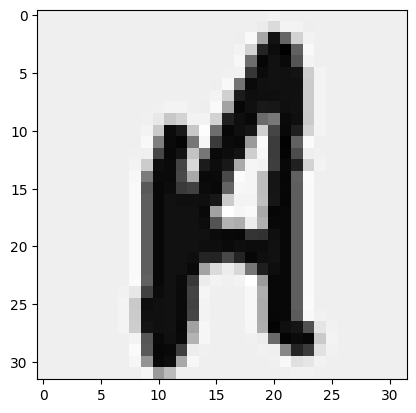

In [21]:
train_data = scipy.io.loadmat("/content/data/nist36_train.mat")
valid_data = scipy.io.loadmat("/content/data/nist36_valid.mat")
test_data = scipy.io.loadmat("/content/data/nist36_test.mat")

train_x, train_y = train_data["train_data"], train_data["train_labels"]
valid_x, valid_y = valid_data["valid_data"], valid_data["valid_labels"]
test_x, test_y = test_data["test_data"], test_data["test_labels"]

# view the data
plt.imshow(train_x[0].reshape(32, 32).T, cmap="gray")
plt.show()

In [ ]:
############################## Q 3.1 ##############################
def evaluate(
    x: np.ndarray, y: np.ndarray, params: dict[str, Any]
) -> tuple[float, float]:
    """Average cross-entropy loss and accuracy of the current network on a dataset."""
    h1 = forward(x, params, "layer1", sigmoid)
    probs = forward(h1, params, "output", softmax)
    loss, acc = compute_loss_and_acc(y, probs)
    return loss / x.shape[0], acc


def train_classifier(
    max_iters: int = 50,
    batch_size: int = 8,
    learning_rate: float = 0.002,
    hidden_size: int = 64,
) -> tuple[
    dict[str, Any], list[float], list[float], list[float], list[float], np.ndarray
]:
    """Train a classifier on the NIST36 dataset."""
    global rng
    rng = np.random.default_rng(seed=0)  # reset rng for reproducibility

    batches = get_random_batches(train_x, train_y, batch_size)

    params = {}
    # initialize layers
    initialize_weights(train_x.shape[1], hidden_size, params, "layer1")
    initialize_weights(hidden_size, train_y.shape[1], params, "output")
    layer1_W_initial = np.copy(params["Wlayer1"])  # copy for Q3.3

    train_loss: list[float] = []
    valid_loss: list[float] = []
    train_acc: list[float] = []
    valid_acc: list[float] = []

    def record_metrics() -> None:
        """Record training and validation loss and accuracy for plotting."""
        loss, acc = evaluate(train_x, train_y, params)
        train_loss.append(loss)
        train_acc.append(acc)
        loss, acc = evaluate(valid_x, valid_y, params)
        valid_loss.append(loss)
        valid_acc.append(acc)

    record_metrics()  # the untrained network, i.e. epoch 0
    for itr in range(max_iters):
        total_loss = 0
        avg_acc = 0
        for xb, yb in batches:
          #Forward
          hidden = forward(xb, params, "layer1", sigmoid)
          probs = forward(hidden, params, "output", softmax)

          #Loss & Accuracy
          loss, acc = compute_loss_and_acc(yb, probs)
          total_loss += loss
          avg_acc += acc * xb.shape[0]

          #Backward
          delta = probs - yb
          delta = backward(delta, params, "output", linear_deriv)
          backward(delta, params, "layer1", sigmoid_deriv)

          #training
          params["Woutput"] -= learning_rate * params["grad_Woutput"]
          params["boutput"] -= learning_rate * params["grad_boutput"]
          params["Wlayer1"] -= learning_rate * params["grad_Wlayer1"]
          params["blayer1"] -= learning_rate * params["grad_blayer1"]

        avg_acc /= train_x.shape[0]

        record_metrics()
        if itr % 2 == 0:
            print(f"itr: {itr:02d}   loss: {total_loss:.2f}   acc: {avg_acc:.2f}")

    # report validation accuracy; aim for 75%
    print("Validation accuracy: ", valid_acc[-1])

    # compute and report test accuracy
    _, test_acc = evaluate(test_x, test_y, params)
    print("Test accuracy: ", test_acc)

    # save the final network
    saved_params = {k: v for k, v in params.items() if "_" not in k}
    with open("/content/q3_weights.pickle", "wb") as handle:
        pickle.dump(saved_params, handle, protocol=pickle.HIGHEST_PROTOCOL)

    return params, train_loss, valid_loss, train_acc, valid_acc, layer1_W_initial


(
    params_classifier,
    train_loss_classifier,
    valid_loss_classifier,
    train_acc_classifier,
    valid_acc_classifier,
    layer1_W_initial,
) = train_classifier()

itr: 00   loss: 36834.12   acc: 0.12
itr: 02   loss: 25886.13   acc: 0.47
itr: 04   loss: 18987.00   acc: 0.60
itr: 06   loss: 15574.38   acc: 0.64
itr: 08   loss: 13709.31   acc: 0.67
itr: 10   loss: 12509.62   acc: 0.69
itr: 12   loss: 11640.26   acc: 0.71
itr: 14   loss: 10959.43   acc: 0.73
itr: 16   loss: 10398.59   acc: 0.74
itr: 18   loss: 9920.61   acc: 0.75
itr: 20   loss: 9503.29   acc: 0.76
itr: 22   loss: 9132.19   acc: 0.77
itr: 24   loss: 8797.36   acc: 0.78
itr: 26   loss: 8491.70   acc: 0.79
itr: 28   loss: 8210.04   acc: 0.80
itr: 30   loss: 7948.51   acc: 0.80
itr: 32   loss: 7704.21   acc: 0.81
itr: 34   loss: 7474.87   acc: 0.81
itr: 36   loss: 7258.67   acc: 0.82
itr: 38   loss: 7054.16   acc: 0.83
itr: 40   loss: 6860.13   acc: 0.83
itr: 42   loss: 6675.60   acc: 0.84
itr: 44   loss: 6499.77   acc: 0.84
itr: 46   loss: 6332.00   acc: 0.84
itr: 48   loss: 6171.73   acc: 0.85
Validation accuracy:  0.7616666666666667
Test accuracy:  0.7727777777777778


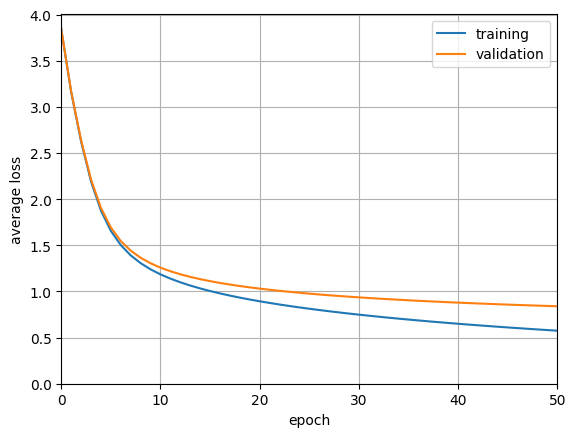

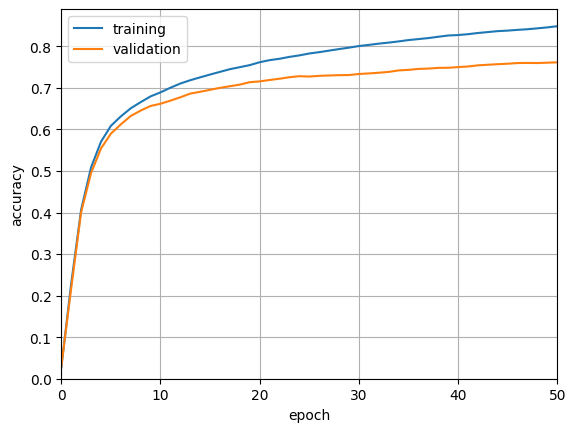

In [ ]:
def plot_loss_and_acc(
    train_loss: list[float],
    valid_loss: list[float],
    train_acc: list[float],
    valid_acc: list[float],
) -> None:
    plot_curves({"training": train_loss, "validation": valid_loss}, "average loss")
    plot_curves({"training": train_acc, "validation": valid_acc}, "accuracy")


plot_loss_and_acc(
    train_loss_classifier,
    valid_loss_classifier,
    train_acc_classifier,
    valid_acc_classifier,
)

## Q3.2 (3 points)

The provided code will visualize the first layer weights as 64 32x32 images, both immediately after initialization and after full training. Generate both visualizations. Comment on the learned weights and compare them to the initialized weights. Do you notice any patterns?

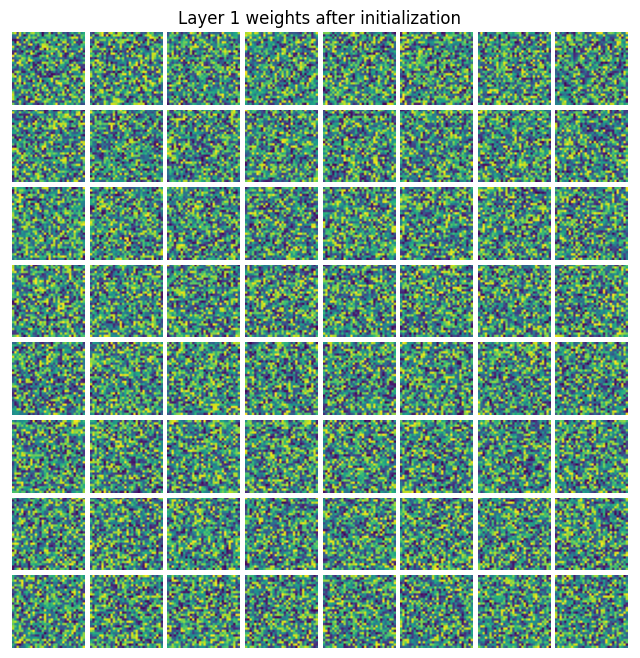

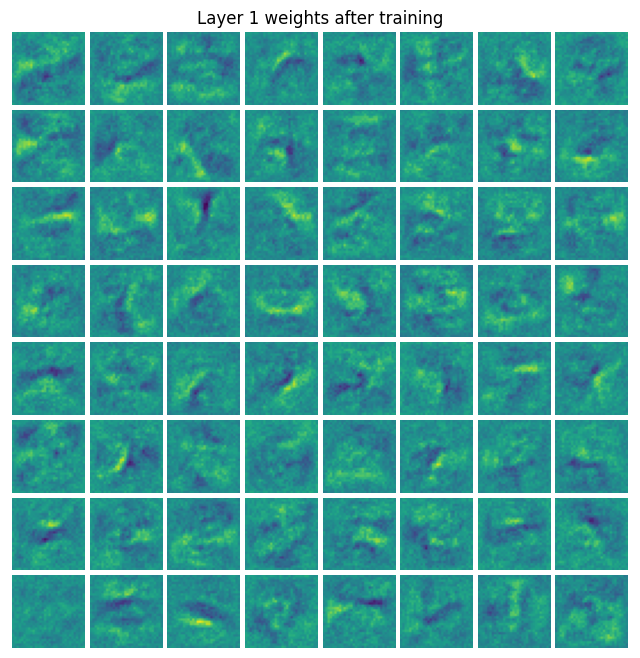

In [ ]:
############################## Q 3.2 ##############################
def show_layer1_weights(W: np.ndarray, title: str) -> None:
    """Show each column of a first-layer weight array as a 32x32 weight image."""
    # a symmetric color scale keeps positive and negative weights comparable
    v = np.max(np.abs(W))
    show_image_grid(
        W.T, nrows_ncols=(8, 8), title=title, figsize=(8, 8), vmin=-v, vmax=v
    )


show_layer1_weights(layer1_W_initial, "Layer 1 weights after initialization")
show_layer1_weights(params_classifier["Wlayer1"], "Layer 1 weights after training")

---

Learned weights are more organized and clear in patterns and features.

---

## Q3.3 (3 points)

Use the code in Q3.1 to train and generate accuracy and loss plots for each of these three networks:

1. one with 10 times your tuned learning rate,
2. one with one-tenth your tuned learning rate, and
3. one with your tuned learning rate.
    
Include a total of six plots (two will be the same from Q3.1). Comment on how the learning rates affect the training, and report the final accuracy of the best network on the test set. *Hint: use fixed random seeds to improve reproducibility.*

---

$10\times$ tuned learning rate: Training is much noisier, with noticeable fluctuations in both loss and accuracy. The large updates cause the optimizer to overshoot good parameter values, so although it learns quickly at first, convergence is unstable. The final test accuracy is about \(66.78\%\).

$0.1\times$ tuned learning rate: The loss decreases very smoothly, but learning is much slower. After 50 epochs the model has not converged as far as the others because each parameter update is very small. The final test accuracy is about \(62.78\%\).

Tuned learning rate: This gives the best balance between convergence speed and stability. The loss decreases steadily while the training and validation accuracies increase substantially, giving the best performance among the three models. The final test accuracy is 77.28%.

---

itr: 00   loss: 28867.55   acc: 0.26
itr: 02   loss: 14879.74   acc: 0.60
itr: 04   loss: 12671.45   acc: 0.66
itr: 06   loss: 11752.58   acc: 0.68
itr: 08   loss: 11026.80   acc: 0.70
itr: 10   loss: 11078.24   acc: 0.70
itr: 12   loss: 10694.63   acc: 0.70
itr: 14   loss: 10539.51   acc: 0.71
itr: 16   loss: 10257.62   acc: 0.72
itr: 18   loss: 10416.25   acc: 0.71
itr: 20   loss: 10310.81   acc: 0.71
itr: 22   loss: 10031.60   acc: 0.72
itr: 24   loss: 9514.80   acc: 0.73
itr: 26   loss: 9610.93   acc: 0.73
itr: 28   loss: 9697.75   acc: 0.72
itr: 30   loss: 9252.13   acc: 0.75
itr: 32   loss: 9224.07   acc: 0.74
itr: 34   loss: 9099.63   acc: 0.74
itr: 36   loss: 9002.58   acc: 0.74
itr: 38   loss: 8594.51   acc: 0.76
itr: 40   loss: 8424.00   acc: 0.76
itr: 42   loss: 7992.19   acc: 0.77
itr: 44   loss: 7908.32   acc: 0.77
itr: 46   loss: 7753.55   acc: 0.78
itr: 48   loss: 7788.43   acc: 0.77
Validation accuracy:  0.6725
Test accuracy:  0.6677777777777778


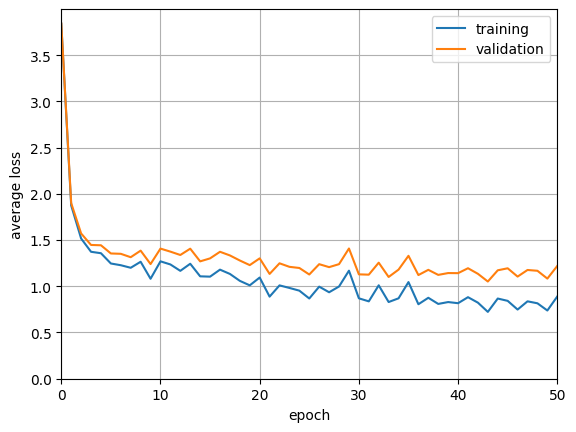

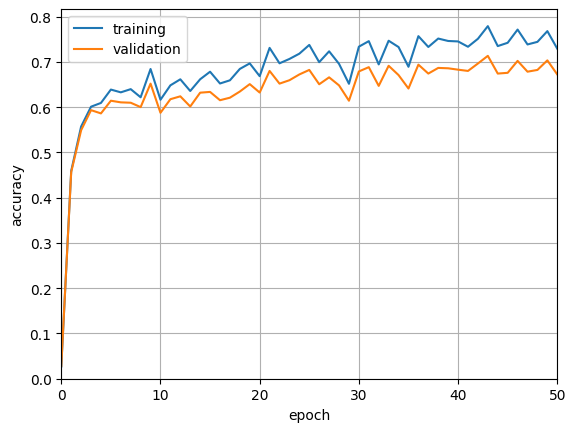

In [ ]:
############################## The one with 10 times your tuned learning rate ##############################
def evaluate(
    x: np.ndarray, y: np.ndarray, params: dict[str, Any]
) -> tuple[float, float]:
    """Average cross-entropy loss and accuracy of the current network on a dataset."""
    h1 = forward(x, params, "layer1", sigmoid)
    probs = forward(h1, params, "output", softmax)
    loss, acc = compute_loss_and_acc(y, probs)
    return loss / x.shape[0], acc


def train_classifier(
    max_iters: int = 50,
    batch_size: int = 8,
    learning_rate: float = 0.02,
    hidden_size: int = 64,
) -> tuple[
    dict[str, Any], list[float], list[float], list[float], list[float], np.ndarray
]:
    """Train a classifier on the NIST36 dataset."""
    global rng
    rng = np.random.default_rng(seed=0)  # reset rng for reproducibility

    batches = get_random_batches(train_x, train_y, batch_size)

    params = {}
    # initialize layers
    initialize_weights(train_x.shape[1], hidden_size, params, "layer1")
    initialize_weights(hidden_size, train_y.shape[1], params, "output")
    layer1_W_initial = np.copy(params["Wlayer1"])  # copy for Q3.3

    train_loss: list[float] = []
    valid_loss: list[float] = []
    train_acc: list[float] = []
    valid_acc: list[float] = []

    def record_metrics() -> None:
        """Record training and validation loss and accuracy for plotting."""
        loss, acc = evaluate(train_x, train_y, params)
        train_loss.append(loss)
        train_acc.append(acc)
        loss, acc = evaluate(valid_x, valid_y, params)
        valid_loss.append(loss)
        valid_acc.append(acc)

    record_metrics()  # the untrained network, i.e. epoch 0
    for itr in range(max_iters):
        total_loss = 0
        avg_acc = 0
        for xb, yb in batches:
          #Forward
          hidden = forward(xb, params, "layer1", sigmoid)
          probs = forward(hidden, params, "output", softmax)

          #Loss & Accuracy
          loss, acc = compute_loss_and_acc(yb, probs)
          total_loss += loss
          avg_acc += acc * xb.shape[0]

          #Backward
          delta = probs - yb
          delta = backward(delta, params, "output", linear_deriv)
          backward(delta, params, "layer1", sigmoid_deriv)

          #training
          params["Woutput"] -= learning_rate * params["grad_Woutput"]
          params["boutput"] -= learning_rate * params["grad_boutput"]
          params["Wlayer1"] -= learning_rate * params["grad_Wlayer1"]
          params["blayer1"] -= learning_rate * params["grad_blayer1"]

        avg_acc /= train_x.shape[0]

        record_metrics()
        if itr % 2 == 0:
            print(f"itr: {itr:02d}   loss: {total_loss:.2f}   acc: {avg_acc:.2f}")

    # report validation accuracy; aim for 75%
    print("Validation accuracy: ", valid_acc[-1])

    # compute and report test accuracy
    _, test_acc = evaluate(test_x, test_y, params)
    print("Test accuracy: ", test_acc)

    # save the final network
    saved_params = {k: v for k, v in params.items() if "_" not in k}
    with open("/content/q3_weights.pickle", "wb") as handle:
        pickle.dump(saved_params, handle, protocol=pickle.HIGHEST_PROTOCOL)

    return params, train_loss, valid_loss, train_acc, valid_acc, layer1_W_initial


(
    params_classifier,
    train_loss_classifier,
    valid_loss_classifier,
    train_acc_classifier,
    valid_acc_classifier,
    layer1_W_initial,
) = train_classifier()

def plot_loss_and_acc(
    train_loss: list[float],
    valid_loss: list[float],
    train_acc: list[float],
    valid_acc: list[float],
) -> None:
    plot_curves({"training": train_loss, "validation": valid_loss}, "average loss")
    plot_curves({"training": train_acc, "validation": valid_acc}, "accuracy")


plot_loss_and_acc(
    train_loss_classifier,
    valid_loss_classifier,
    train_acc_classifier,
    valid_acc_classifier,
)

itr: 00   loss: 38899.32   acc: 0.04
itr: 02   loss: 37704.63   acc: 0.11
itr: 04   loss: 36710.47   acc: 0.21
itr: 06   loss: 35579.26   acc: 0.28
itr: 08   loss: 34374.32   acc: 0.32
itr: 10   loss: 33133.12   acc: 0.36
itr: 12   loss: 31881.02   acc: 0.39
itr: 14   loss: 30647.96   acc: 0.42
itr: 16   loss: 29452.63   acc: 0.44
itr: 18   loss: 28303.90   acc: 0.47
itr: 20   loss: 27208.95   acc: 0.49
itr: 22   loss: 26171.73   acc: 0.50
itr: 24   loss: 25192.81   acc: 0.52
itr: 26   loss: 24271.50   acc: 0.54
itr: 28   loss: 23406.80   acc: 0.55
itr: 30   loss: 22597.42   acc: 0.56
itr: 32   loss: 21841.74   acc: 0.57
itr: 34   loss: 21137.78   acc: 0.58
itr: 36   loss: 20483.19   acc: 0.59
itr: 38   loss: 19875.34   acc: 0.60
itr: 40   loss: 19311.38   acc: 0.61
itr: 42   loss: 18788.34   acc: 0.62
itr: 44   loss: 18303.23   acc: 0.62
itr: 46   loss: 17853.08   acc: 0.63
itr: 48   loss: 17435.04   acc: 0.63
Validation accuracy:  0.6213888888888889
Test accuracy:  0.6277777777777778

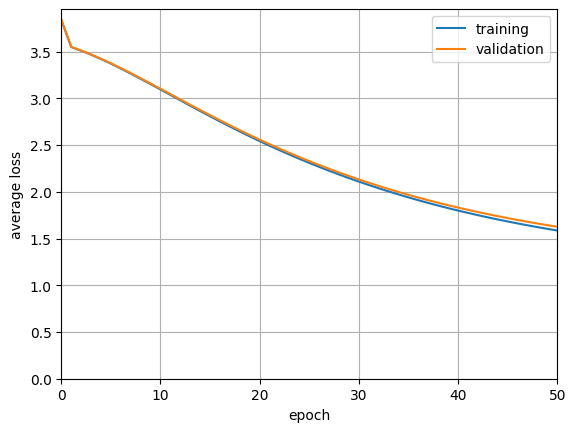

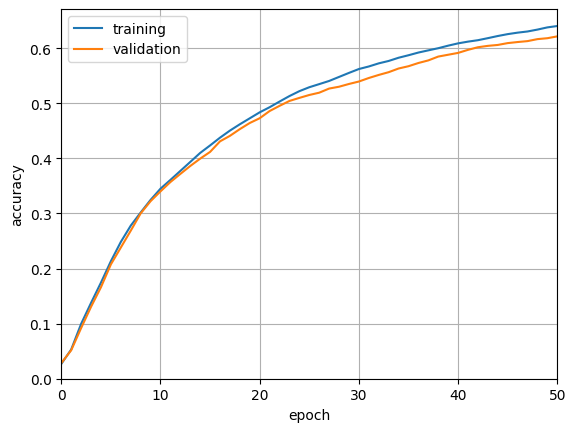

In [ ]:
############################## one with one-tenth your tuned learning rate ##############################
def evaluate(
    x: np.ndarray, y: np.ndarray, params: dict[str, Any]
) -> tuple[float, float]:
    """Average cross-entropy loss and accuracy of the current network on a dataset."""
    h1 = forward(x, params, "layer1", sigmoid)
    probs = forward(h1, params, "output", softmax)
    loss, acc = compute_loss_and_acc(y, probs)
    return loss / x.shape[0], acc

def train_classifier(
    max_iters: int = 50,
    batch_size: int = 8,
    learning_rate: float = 0.0002,
    hidden_size: int = 64,
) -> tuple[
    dict[str, Any], list[float], list[float], list[float], list[float], np.ndarray
]:
    """Train a classifier on the NIST36 dataset."""
    global rng
    rng = np.random.default_rng(seed=0)  # reset rng for reproducibility

    batches = get_random_batches(train_x, train_y, batch_size)

    params = {}
    # initialize layers
    initialize_weights(train_x.shape[1], hidden_size, params, "layer1")
    initialize_weights(hidden_size, train_y.shape[1], params, "output")
    layer1_W_initial = np.copy(params["Wlayer1"])  # copy for Q3.3

    train_loss: list[float] = []
    valid_loss: list[float] = []
    train_acc: list[float] = []
    valid_acc: list[float] = []

    def record_metrics() -> None:
        """Record training and validation loss and accuracy for plotting."""
        loss, acc = evaluate(train_x, train_y, params)
        train_loss.append(loss)
        train_acc.append(acc)
        loss, acc = evaluate(valid_x, valid_y, params)
        valid_loss.append(loss)
        valid_acc.append(acc)

    record_metrics()  # the untrained network, i.e. epoch 0
    for itr in range(max_iters):
        total_loss = 0
        avg_acc = 0
        for xb, yb in batches:
          #Forward
          hidden = forward(xb, params, "layer1", sigmoid)
          probs = forward(hidden, params, "output", softmax)

          #Loss & Accuracy
          loss, acc = compute_loss_and_acc(yb, probs)
          total_loss += loss
          avg_acc += acc * xb.shape[0]

          #Backward
          delta = probs - yb
          delta = backward(delta, params, "output", linear_deriv)
          backward(delta, params, "layer1", sigmoid_deriv)

          #training
          params["Woutput"] -= learning_rate * params["grad_Woutput"]
          params["boutput"] -= learning_rate * params["grad_boutput"]
          params["Wlayer1"] -= learning_rate * params["grad_Wlayer1"]
          params["blayer1"] -= learning_rate * params["grad_blayer1"]

        avg_acc /= train_x.shape[0]

        record_metrics()
        if itr % 2 == 0:
            print(f"itr: {itr:02d}   loss: {total_loss:.2f}   acc: {avg_acc:.2f}")

    # report validation accuracy; aim for 75%
    print("Validation accuracy: ", valid_acc[-1])

    # compute and report test accuracy
    _, test_acc = evaluate(test_x, test_y, params)
    print("Test accuracy: ", test_acc)

    # save the final network
    saved_params = {k: v for k, v in params.items() if "_" not in k}
    with open("/content/q3_weights.pickle", "wb") as handle:
        pickle.dump(saved_params, handle, protocol=pickle.HIGHEST_PROTOCOL)

    return params, train_loss, valid_loss, train_acc, valid_acc, layer1_W_initial


(
    params_classifier,
    train_loss_classifier,
    valid_loss_classifier,
    train_acc_classifier,
    valid_acc_classifier,
    layer1_W_initial,
) = train_classifier()

def plot_loss_and_acc(
    train_loss: list[float],
    valid_loss: list[float],
    train_acc: list[float],
    valid_acc: list[float],
) -> None:
    plot_curves({"training": train_loss, "validation": valid_loss}, "average loss")
    plot_curves({"training": train_acc, "validation": valid_acc}, "accuracy")


plot_loss_and_acc(
    train_loss_classifier,
    valid_loss_classifier,
    train_acc_classifier,
    valid_acc_classifier,
)

itr: 00   loss: 36834.12   acc: 0.12
itr: 02   loss: 25886.13   acc: 0.47
itr: 04   loss: 18987.00   acc: 0.60
itr: 06   loss: 15574.38   acc: 0.64
itr: 08   loss: 13709.31   acc: 0.67
itr: 10   loss: 12509.62   acc: 0.69
itr: 12   loss: 11640.26   acc: 0.71
itr: 14   loss: 10959.43   acc: 0.73
itr: 16   loss: 10398.59   acc: 0.74
itr: 18   loss: 9920.61   acc: 0.75
itr: 20   loss: 9503.29   acc: 0.76
itr: 22   loss: 9132.19   acc: 0.77
itr: 24   loss: 8797.36   acc: 0.78
itr: 26   loss: 8491.70   acc: 0.79
itr: 28   loss: 8210.04   acc: 0.80
itr: 30   loss: 7948.51   acc: 0.80
itr: 32   loss: 7704.21   acc: 0.81
itr: 34   loss: 7474.87   acc: 0.81
itr: 36   loss: 7258.67   acc: 0.82
itr: 38   loss: 7054.16   acc: 0.83
itr: 40   loss: 6860.13   acc: 0.83
itr: 42   loss: 6675.60   acc: 0.84
itr: 44   loss: 6499.77   acc: 0.84
itr: 46   loss: 6332.00   acc: 0.84
itr: 48   loss: 6171.73   acc: 0.85
Validation accuracy:  0.7616666666666667
Test accuracy:  0.7727777777777778


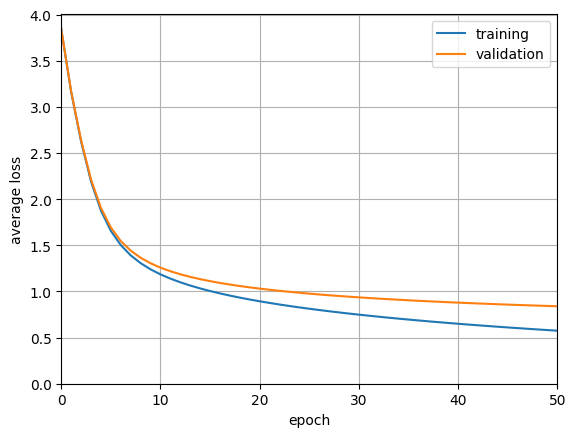

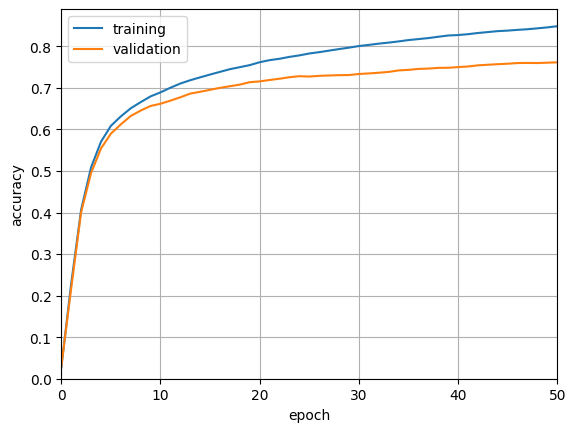

In [ ]:
############################## one with your tuned learning rate ##############################
def evaluate(
    x: np.ndarray, y: np.ndarray, params: dict[str, Any]
) -> tuple[float, float]:
    """Average cross-entropy loss and accuracy of the current network on a dataset."""
    h1 = forward(x, params, "layer1", sigmoid)
    probs = forward(h1, params, "output", softmax)
    loss, acc = compute_loss_and_acc(y, probs)
    return loss / x.shape[0], acc


def train_classifier(
    max_iters: int = 50,
    batch_size: int = 8,
    learning_rate: float = 0.002,
    hidden_size: int = 64,
) -> tuple[
    dict[str, Any], list[float], list[float], list[float], list[float], np.ndarray
]:
    """Train a classifier on the NIST36 dataset."""
    global rng
    rng = np.random.default_rng(seed=0)  # reset rng for reproducibility

    batches = get_random_batches(train_x, train_y, batch_size)

    params = {}
    # initialize layers
    initialize_weights(train_x.shape[1], hidden_size, params, "layer1")
    initialize_weights(hidden_size, train_y.shape[1], params, "output")
    layer1_W_initial = np.copy(params["Wlayer1"])  # copy for Q3.3

    train_loss: list[float] = []
    valid_loss: list[float] = []
    train_acc: list[float] = []
    valid_acc: list[float] = []

    def record_metrics() -> None:
        """Record training and validation loss and accuracy for plotting."""
        loss, acc = evaluate(train_x, train_y, params)
        train_loss.append(loss)
        train_acc.append(acc)
        loss, acc = evaluate(valid_x, valid_y, params)
        valid_loss.append(loss)
        valid_acc.append(acc)

    record_metrics()  # the untrained network, i.e. epoch 0
    for itr in range(max_iters):
        total_loss = 0
        avg_acc = 0
        for xb, yb in batches:
          #Forward
          hidden = forward(xb, params, "layer1", sigmoid)
          probs = forward(hidden, params, "output", softmax)

          #Loss & Accuracy
          loss, acc = compute_loss_and_acc(yb, probs)
          total_loss += loss
          avg_acc += acc * xb.shape[0]

          #Backward
          delta = probs - yb
          delta = backward(delta, params, "output", linear_deriv)
          backward(delta, params, "layer1", sigmoid_deriv)

          #training
          params["Woutput"] -= learning_rate * params["grad_Woutput"]
          params["boutput"] -= learning_rate * params["grad_boutput"]
          params["Wlayer1"] -= learning_rate * params["grad_Wlayer1"]
          params["blayer1"] -= learning_rate * params["grad_blayer1"]

        avg_acc /= train_x.shape[0]

        record_metrics()
        if itr % 2 == 0:
            print(f"itr: {itr:02d}   loss: {total_loss:.2f}   acc: {avg_acc:.2f}")

    # report validation accuracy; aim for 75%
    print("Validation accuracy: ", valid_acc[-1])

    # compute and report test accuracy
    _, test_acc = evaluate(test_x, test_y, params)
    print("Test accuracy: ", test_acc)

    # save the final network
    saved_params = {k: v for k, v in params.items() if "_" not in k}
    with open("/content/q3_weights.pickle", "wb") as handle:
        pickle.dump(saved_params, handle, protocol=pickle.HIGHEST_PROTOCOL)

    return params, train_loss, valid_loss, train_acc, valid_acc, layer1_W_initial


(
    params_classifier,
    train_loss_classifier,
    valid_loss_classifier,
    train_acc_classifier,
    valid_acc_classifier,
    layer1_W_initial,
) = train_classifier()
def plot_loss_and_acc(
    train_loss: list[float],
    valid_loss: list[float],
    train_acc: list[float],
    valid_acc: list[float],
) -> None:
    plot_curves({"training": train_loss, "validation": valid_loss}, "average loss")
    plot_curves({"training": train_acc, "validation": valid_acc}, "accuracy")


plot_loss_and_acc(
    train_loss_classifier,
    valid_loss_classifier,
    train_acc_classifier,
    valid_acc_classifier,
)

## Q3.4 (3 points)

Compute and visualize the confusion matrix of the test data for your best model. Comment on the top few pairs of classes that are most commonly confused.

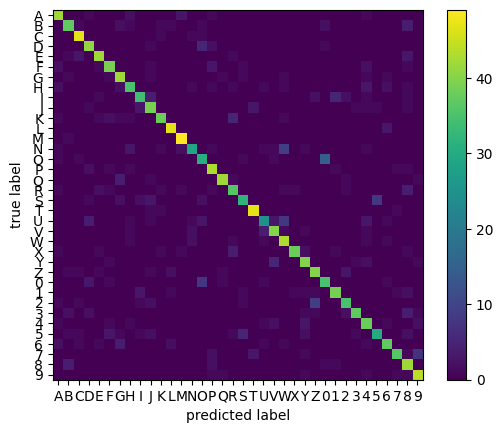

In [ ]:
############################## Q 3.4 ##############################
def show_confusion_matrix(params: dict[str, Any]) -> None:
    """Compute and plot the confusion matrix of a trained classifier on the test set."""
    confusion_matrix = np.zeros((test_y.shape[1], test_y.shape[1]))

    # compute confusion matrix
    hidden = forward(test_x, params, "layer1", sigmoid)
    pred = forward(hidden, params, "output", softmax)

    for i in range(test_y.shape[0]):
        confusion_matrix[np.argmax(test_y[i]), np.argmax(pred[i])] += 1

    # visualize confusion matrix
    plt.imshow(confusion_matrix, interpolation="nearest")
    plt.xticks(np.arange(len(CLASSES)), CLASSES)
    plt.yticks(np.arange(len(CLASSES)), CLASSES)
    plt.xlabel("predicted label")
    plt.ylabel("true label")
    plt.colorbar()
    plt.show()


show_confusion_matrix(params_classifier)

---

The most commonly confused pairs appear to be characters with similar visual shapes. In particular, the strongest off-diagonal confusion is between O and 0, which is expected because uppercase “O” and the digit “0” look very similar. Other noticeable confusions include 2 and Z, N and W, U and W, and S and 5.

---

# Q4 Image Compression with Autoencoders

An autoencoder is a neural network that is trained to attempt to copy its input to its output, but it usually allows copying only approximately. This is typically achieved by restricting the number of hidden nodes inside the autoencoder; in other words, the autoencoder would be forced to learn to *represent* data with this limited number of hidden nodes. This is a useful way of learning compressed representations.

In this section, we will continue using the NIST36 dataset you have from the previous questions.

## Q4.1 Building the Autoencoder

### Q4.1 (4 points)

Due to the difficulty in training auto-encoders, we have to move to the $\mathop{\text{relu}}(x) = \max(x,0)$ activation function. It is provided for you. We will build an autoencoder with the layers listed below. Initialize the layers with the `initialize_weights()` function you wrote in Q2.1.2.

- 1024 to 32 dimensions, followed by a ReLU
- 32 to 32 dimensions, followed by a ReLU
- 32 to 32 dimensions, followed by a ReLU
- 32 to 1024 dimensions, followed by a sigmoid (this normalizes the image output for us)

In [12]:
# here we provide the relu activation and its derivative for you


def relu(x: np.ndarray) -> np.ndarray:
    return np.maximum(x, 0)


def relu_deriv(x: np.ndarray) -> np.ndarray:
    return (x > 0).astype(float)


############################## Q 4.1 ##############################
def initialize_autoencoder() -> dict[str, Any]:
    """Initialize the autoencoder layers, returning a dictionary of parameters."""
    params = {}
    initialize_weights(1024, 32, params, name="layer_1")
    initialize_weights(32, 32, params, name="layer_2")
    initialize_weights(32, 32, params, name="layer_3")
    initialize_weights(32, 1024, params, name="output")
    return params

## Q4.2 Training the Autoencoder

### Q4.2.1 (5 points)

To help even more with convergence speed, we will implement momentum. Now, instead of updating $W = W - \alpha \frac{\partial J}{\partial W}$, we will use the update rules $M_W = 0.9 M_W - \alpha \frac{\partial J}{\partial W}$ and $W = W + M_W$. To implement momentum, populate the parameters dictionary with zero-initialized momentum accumulators $M$, one for each parameter. Then simply perform both update equations for every batch.

### Q4.2.2 (6 points)

Using the provided default settings, train the network for 100 epochs. The loss function that you will use is the total squared error for the output image compared to the input image (they should be the same!). Plot the training loss curve. What do you observe?

itr: 00 	 loss: 839666.15
itr: 02 	 loss: 582216.12
itr: 04 	 loss: 510557.78
itr: 06 	 loss: 465472.41
itr: 08 	 loss: 439156.77
itr: 10 	 loss: 430736.66
itr: 12 	 loss: 425339.64
itr: 14 	 loss: 409909.28
itr: 16 	 loss: 398106.95
itr: 18 	 loss: 394365.79
itr: 20 	 loss: 391551.56
itr: 22 	 loss: 389073.84
itr: 24 	 loss: 388057.31
itr: 26 	 loss: 386133.16
itr: 28 	 loss: 383898.80
itr: 30 	 loss: 382272.19
itr: 32 	 loss: 377851.37
itr: 34 	 loss: 368855.04
itr: 36 	 loss: 366290.11
itr: 38 	 loss: 364580.89
itr: 40 	 loss: 361482.40
itr: 42 	 loss: 358689.04
itr: 44 	 loss: 357386.71
itr: 46 	 loss: 355998.59
itr: 48 	 loss: 355022.56
itr: 50 	 loss: 354286.91
itr: 52 	 loss: 353611.56
itr: 54 	 loss: 353070.99
itr: 56 	 loss: 352718.70
itr: 58 	 loss: 351622.67
itr: 60 	 loss: 350839.50
itr: 62 	 loss: 349332.79
itr: 64 	 loss: 348241.44
itr: 66 	 loss: 346479.57
itr: 68 	 loss: 341884.32
itr: 70 	 loss: 338862.77
itr: 72 	 loss: 337147.20
itr: 74 	 loss: 336082.16
itr: 76 	 lo

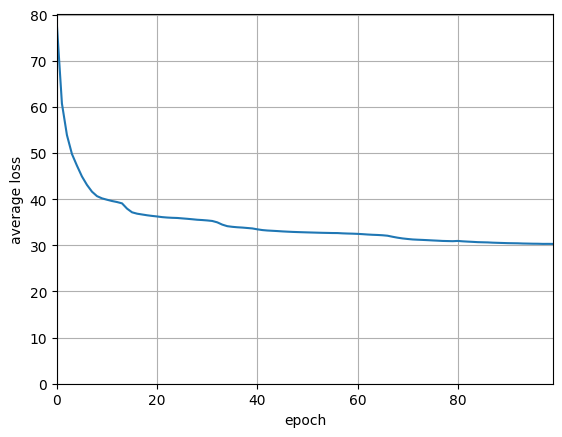

In [23]:
########################### Q 4.2.1 & Q 4.2.2 ########################
def initialize_autoencoder() -> dict[str, Any]:
    """Initialize the autoencoder layers, returning a dictionary of parameters."""
    params = {}
    initialize_weights(1024, 32, params, name="layer1")
    initialize_weights(32, 32, params, name="layer2")
    initialize_weights(32, 32, params, name="layer3")
    initialize_weights(32, 1024, params, name="output")

    # Initialize momentum accumulators with correct sizes and names
    params["M_Wlayer1"] = np.zeros(params["Wlayer1"].shape)
    params["M_blayer1"] = np.zeros(params["blayer1"].shape)

    params["M_Wlayer2"] = np.zeros(params["Wlayer2"].shape)
    params["M_blayer2"] = np.zeros(params["blayer2"].shape)

    params["M_Wlayer3"] = np.zeros(params["Wlayer3"].shape)
    params["M_blayer3"] = np.zeros(params["blayer3"].shape)

    params["M_Woutput"] = np.zeros(params["Woutput"].shape)
    params["M_boutput"] = np.zeros(params["boutput"].shape)
    return params

def train_autoencoder(
    max_iters: int = 100,
    batch_size: int = 36,
    learning_rate: float = 3e-5,
    lr_rate: int = 20,
) -> dict[str, Any]:
    """Train an autoencoder on the NIST36 dataset."""
    global rng
    rng = np.random.default_rng(seed=0)  # reset rng for reproducibility

    batches = get_random_batches(train_x, np.ones((train_x.shape[0], 1)), batch_size)
    params = initialize_autoencoder()

    # should look like your previous training loops
    losses = []
    for itr in range(max_iters):
        total_loss = 0
        for xb, _ in batches:
          #Forward
          hidden1 = forward(xb, params, "layer1",relu)
          hidden2 = forward(hidden1, params, "layer2",relu)
          hidden3 = forward(hidden2, params, "layer3",relu)
          output = forward(hidden3, params, "output",sigmoid)

          #Loss
          total_loss += np.sum(np.square(output-xb))

          #Backward
          delta = 2*(output-xb)
          delta = backward(delta, params, "output", sigmoid_deriv)
          delta = backward(delta, params, "layer3", relu_deriv)
          delta = backward(delta, params, "layer2", relu_deriv)
          backward(delta, params, "layer1",relu_deriv)


          #Training
          params["M_Woutput"] = (0.9 * params["M_Woutput"] - learning_rate * params["grad_Woutput"])
          params["M_boutput"] = (0.9 * params["M_boutput"] - learning_rate * params["grad_boutput"])

          params["Woutput"] += params["M_Woutput"]
          params["boutput"] += params["M_boutput"]

          params["M_Wlayer3"] = (0.9 * params["M_Wlayer3"] - learning_rate * params["grad_Wlayer3"])
          params["M_blayer3"] = (0.9 * params["M_blayer3"] - learning_rate * params["grad_blayer3"])

          params["Wlayer3"] += params["M_Wlayer3"]
          params["blayer3"] += params["M_blayer3"]

          params["M_Wlayer2"] = (0.9 * params["M_Wlayer2"] - learning_rate * params["grad_Wlayer2"])
          params["M_blayer2"] = (0.9 * params["M_blayer2"] - learning_rate * params["grad_blayer2"])

          params["Wlayer2"] += params["M_Wlayer2"]
          params["blayer2"] += params["M_blayer2"]

          params["M_Wlayer1"] = (0.9 * params["M_Wlayer1"] - learning_rate * params["grad_Wlayer1"])
          params["M_blayer1"] = (0.9 * params["M_blayer1"] - learning_rate * params["grad_blayer1"])

          params["Wlayer1"] += params["M_Wlayer1"]
          params["blayer1"] += params["M_blayer1"]


            # training loop can be exactly the same as q2!
            # your loss is now the total squared error, i.e. the sum of (x-y)^2
            # delta is the d/dx of (x-y)^2
            # to implement momentum just use 'M_'+name variables as momentum accumulators to keep a saved value over steps


        losses.append(total_loss / train_x.shape[0])
        if itr % 2 == 0:
            print(f"itr: {itr:02d} \t loss: {total_loss:.2f}")
        if itr % lr_rate == lr_rate - 1:
            learning_rate *= 0.9

    plot_curves({"training": losses}, "average loss")

    return params


params_autoencoder = train_autoencoder()

---

We may observe that the training loss decreases rapidly at the beginning, then the rate of improvement slows and the curve gradually flattens.

---

## Q4.3 Evaluating the Autoencoder

### Q4.3.1 (5 points)

Now let's evaluate how well the autoencoder has been trained. Select 5 classes from the total 36 classes in the validation set and for each selected class show 2 validation images and their reconstruction. What differences do you observe in the reconstructed validation images compared to the original ones?

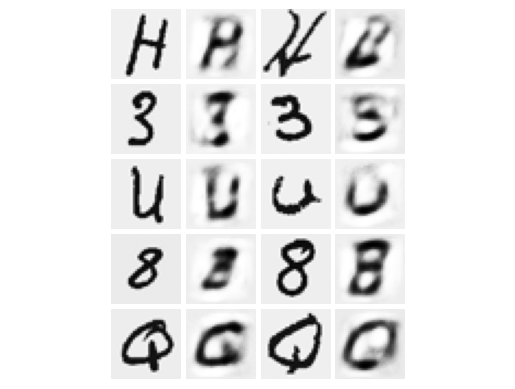

(array([[0.93999549, 0.93999549, 0.93999549, ..., 0.93999549, 0.93999549,
         0.93999549],
        [0.93852734, 0.93852734, 0.93852734, ..., 0.93852734, 0.93852734,
         0.93852734],
        [0.9302024 , 0.9302024 , 0.9302024 , ..., 0.9302024 , 0.9302024 ,
         0.9302024 ],
        ...,
        [0.93160761, 0.93160761, 0.93160761, ..., 0.93160761, 0.93160761,
         0.93160761],
        [0.92773805, 0.92773805, 0.92773805, ..., 0.92773805, 0.92773805,
         0.92773805],
        [0.93562021, 0.93562021, 0.93562021, ..., 0.93562021, 0.93562021,
         0.93562021]]),
 array([[0.95340097, 0.9532865 , 0.95533946, ..., 0.95500502, 0.95344249,
         0.95530663],
        [0.93218854, 0.93110204, 0.93344436, ..., 0.92857044, 0.92983608,
         0.93259116],
        [0.95332845, 0.95260954, 0.95055145, ..., 0.95275621, 0.95188902,
         0.95278075],
        ...,
        [0.93506393, 0.93390458, 0.93637927, ..., 0.93260446, 0.93015745,
         0.93500698],
        [0.9

In [28]:
############################## Q 4.3.1 ##############################
def visualize_reconstructions(labels: list[str]) -> None:
    """Show 2 validation images of each given class, next to their reconstructions."""
    # get 2 validation images from each label to visualize
    sample_rng = np.random.default_rng(seed=0)
    valid_labels = valid_y.argmax(1)
    chosen = np.concatenate(
        [
            sample_rng.choice(
                np.flatnonzero(valid_labels == CLASSES.index(label)), 2, replace=False
            )
            for label in labels
        ]
    )
    visualize_x = valid_x[chosen]

    # run visualize_x through your network using the forward() function you wrote in Q2.2.1
    reconstructed_x = np.array([])

    hidden1 = forward(visualize_x, params_autoencoder, "layer1", relu)

    hidden2 = forward(hidden1, params_autoencoder, "layer2", relu)

    hidden3 = forward(hidden2, params_autoencoder, "layer3", relu)

    reconstructed_x = forward(hidden3, params_autoencoder, "output", sigmoid)

    # show each image next to its reconstruction, two such pairs per row
    show_image_grid(
        [image for pair in zip(visualize_x, reconstructed_x) for image in pair],
        nrows_ncols=(len(labels), 4),
        cmap="gray",
    )


# choose 5 classes (change if you want)
visualize_reconstructions(["H", "3", "U", "8", "Q"])

---

The reconstructions preserve the overall class identity and coarse shape, but compared with the original validation images they are noticeably blurrier, smoother, and less detailed.

---

### Q4.3.2 (5 points)

Let's evaluate the reconstruction quality using Peak Signal-to-noise Ratio (PSNR). PSNR is defined as

$$\text{PSNR} = 20 \times \log_{10}(\text{MAX}_I) - 10\times \log_{10}(\text{MSE})$$

where $\text{MAX}_I$ is the maximum possible pixel value of the image ($\text{MAX}_I = 1$ for images scaled to $[0, 1]$), and $\text{MSE}$ (mean squared error) is computed across all pixels. Report the average PSNR you get from the autoencoder across all images in the validation set (it should be around 15). You may use `skimage.metrics.peak_signal_noise_ratio` for convenience.

In [30]:
############################## Q 4.3.2 ##############################
# evaluate PSNR
from skimage.metrics import peak_signal_noise_ratio
hidden1 = forward(valid_x, params_autoencoder, "layer1", relu)
hidden2 = forward(hidden1, params_autoencoder, "layer2", relu)
hidden3 = forward(hidden2, params_autoencoder, "layer3", relu)
reconstructed_valid_x = forward(hidden3, params_autoencoder, "output", sigmoid)

psnr = np.mean([peak_signal_noise_ratio(valid_x[i],reconstructed_valid_x[i],data_range=1.0) for i in range(len(valid_x))])

print("Average validation PSNR:", psnr)


Average validation PSNR: 15.580564954271273


---

The average PSNR is 15.58%.

---

# Q5 (Extra Credit) Image Generation with a Variational Autoencoder

In the previous section, you trained an autoencoder to compress and reconstruct images. The network learns a *deterministic* mapping from the input image $\mathbf{x}$ to a latent $\mathbf{z}$, and back to a reconstruction $\hat{\mathbf{x}}$. Since the decoder can reconstruct an image from a vector, you might think: *What if we fed a random latent vector into the decoder? Then it could reconstruct the vector into an entirely new image!* Unfortunately, a random latent vector could be very different from the vectors corresponding to real images, so it might not decode into anything meaningful.

The **Variational Autoencoder (VAE)** addresses this by *encouraging the space of latent vectors to follow a Gaussian distribution*, so that we can properly sample a vector from this distribution. Instead of mapping the input to a fixed vector, the VAE's encoder maps it to the parameters of a Gaussian distribution, and the latent vector is then produced by randomly sampling from this distribution.

In this section, you will modify the autoencoder from Q4 to enable it to generate new images. We will use the same dataset as before.

## Q5.1 (Extra Credit) (4 points)

Before we implement the VAE, let's try generating samples with the plain autoencoder.

We will treat the first two layers as the encoder and the last two layers as the decoder. Implement the `sample_decoder(params, num_samples)` function that samples latent vectors $\mathbf{z} \sim \mathcal{N}(0, I)$ and decodes them with the decoder. Visualize 9 samples in a $3 \times 3$ grid using the autoencoder trained in the previous section. Briefly describe what you observe.

You may use `rng.normal()` to sample random numbers from a normal distribution.

In [25]:
############################## Q 5.1 ##############################
def sample_decoder(params: dict[str, Any], num_samples: int) -> list[np.ndarray]:
    """
    Takes the parameters of the network and the number of samples to generate,
    and returns a list of sampled images.
    """
    images = []
    rng = np.random.default_rng()
    z=rng.normal(size=(num_samples, 32))
    hidden = forward(z, params, "layer3", relu)
    image = forward(hidden, params, "output", sigmoid)
    images = image.reshape((num_samples, 32, 32))
    return images

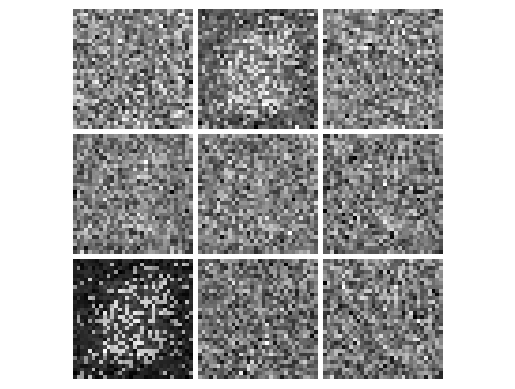

In [26]:
# generate samples using the trained autoencoder
generated_samples = sample_decoder(params_autoencoder, 9)

# visualize the generated samples
show_image_grid(generated_samples, nrows_ncols=(3, 3), cmap="gray")

---

The randomly generated images are mostly noise.

---

## Q5.2 (Extra Credit) (4 points)

Modify the encoder such that instead of producing a single latent vector, it produces two vectors corresponding to $\boldsymbol{\mu}(\mathbf{x})$ and $\log \boldsymbol{\sigma}^2(\mathbf{x})$. Include a brief description of the modified architecture in the writeup.

Initialize the layers of the VAE with the `initialize_weights()` function you wrote in Q2.1.2. Feel free to increase the number of hidden layers or the hidden dimension.

In [27]:
############################## Q 5.2 ##############################
def initialize_vae() -> dict[str, Any]:
    """Initialize the VAE layers, returning a dictionary of parameters."""
    params = {}
    #Encoder
    initialize_weights(1024, 32, params, name="encoder")

    # mu & var
    initialize_weights(32, 32, params, name="mu")
    initialize_weights(32, 32, params, name="logvar")

    # Decoder
    initialize_weights(32, 32, params, name="decoder")
    initialize_weights(32, 1024, params, name="output")
    return params

Describe the changes you made to the parameters.


---

I've set up layers for both mean and variances.

---


## Q5.3 (Extra Credit) (4 points)

To train the VAE, we must sample a latent vector $\mathbf{z}$ from the Gaussian distribution predicted by the encoder. However, directly sampling from $\mathcal{N}(\boldsymbol{\mu}(\mathbf{x}), \boldsymbol{\sigma}^2(\mathbf{x}))$ would prevent gradients from flowing through the sampling operation. To address this, VAEs use the *reparameterization trick*:
$$
\mathbf{z} = \boldsymbol{\mu} + \boldsymbol{\sigma} \odot \boldsymbol{\epsilon}, \quad \boldsymbol{\epsilon} \sim \mathcal{N}(0, I).
$$
Implement the function `reparameterize(mu, logvar)` that performs this operation and returns the sampled latent vector $\mathbf{z}$. You can use `rng.normal()` to generate these samples.

In [39]:
############################## Q 5.3 ##############################
def reparameterize(mu: np.ndarray, logvar: np.ndarray) -> np.ndarray:
    """
    We will use the reparameterization trick to sample from the latent space:
        z = mu + sigma * epsilon
    where epsilon ~ N(0,1) is a random sample from a normal distribution.
    """
    z = np.array([])
    epsilon= rng.normal(size=mu.shape)
    z = mu + np.exp(0.5 * logvar) * epsilon
    return z, epsilon

## Q5.4 (Extra Credit) (4 points)

VAEs include an additional regularization term that encourages the latent distribution to be close to the standard normal distribution. Implement the function `kl_divergence(mu, logvar)` that computes the Kullback-Leibler (KL) divergence. The KL divergence between two normal distributions $P = \mathcal{N}(\mu_1, \sigma_1^2)$ and $Q = \mathcal{N}(\mu_2, \sigma_2^2)$ is

$$D_{KL}(P \| Q) = \log \left( \frac{\sigma_2}{\sigma_1} \right) + \frac{\sigma_1^2 + (\mu_1 - \mu_2)^2}{2 \sigma_2^2} - \frac{1}{2}.$$

Note that the KL divergence is not symmetric: $D_{KL}(P \| Q) \neq D_{KL}(Q \| P)$ in general. For loss computation, we want $D_{KL}(P \| Q)$ where $P$ is the encoder's Gaussian and $Q$ is the standard Gaussian, and we sum the KL divergences over the latent dimensions.

In [31]:
############################## Q 5.4 ##############################
def kl_divergence(mu: np.ndarray, logvar: np.ndarray) -> float:
    """
    Compute the KL divergence between the latent distribution and a standard normal distribution.
    """
    kl = 0.0
    kl = 0.5 * np.sum(np.exp(logvar) + mu**2 - 1 - logvar)
    return kl

## Q5.5 (Extra Credit) (2 points) Training the VAE

Using the components implemented above, train the Variational Autoencoder. The loss function should consist of the reconstruction loss (as in Q4) and the KL divergence term. Include the training loss plot in the writeup.

We have provided the outline of the training loop below. Fill in the missing parts and run the code below to train the VAE.

You may want to modify `reparameterize()` to return `epsilon` to be used during backpropagation.

itr: 00 	 loss: 1279718.31
itr: 02 	 loss: 881032.55
itr: 04 	 loss: 871009.53
itr: 06 	 loss: 865580.25
itr: 08 	 loss: 855987.49
itr: 10 	 loss: 834330.82
itr: 12 	 loss: 812133.79
itr: 14 	 loss: 801352.66
itr: 16 	 loss: 793383.26
itr: 18 	 loss: 787337.56
itr: 20 	 loss: 781326.16
itr: 22 	 loss: 773666.63
itr: 24 	 loss: 764553.47
itr: 26 	 loss: 758504.31
itr: 28 	 loss: 750565.60
itr: 30 	 loss: 742526.38
itr: 32 	 loss: 737668.34
itr: 34 	 loss: 734732.59
itr: 36 	 loss: 730253.42
itr: 38 	 loss: 727517.57
itr: 40 	 loss: 723574.54
itr: 42 	 loss: 721048.98
itr: 44 	 loss: 718460.49
itr: 46 	 loss: 714992.81
itr: 48 	 loss: 711213.09
itr: 50 	 loss: 707590.67
itr: 52 	 loss: 703226.08
itr: 54 	 loss: 700496.14
itr: 56 	 loss: 695336.69
itr: 58 	 loss: 691633.09
itr: 60 	 loss: 687339.37
itr: 62 	 loss: 684838.17
itr: 64 	 loss: 682625.02
itr: 66 	 loss: 680182.84
itr: 68 	 loss: 678153.91
itr: 70 	 loss: 676391.91
itr: 72 	 loss: 674196.77
itr: 74 	 loss: 671796.30
itr: 76 	 l

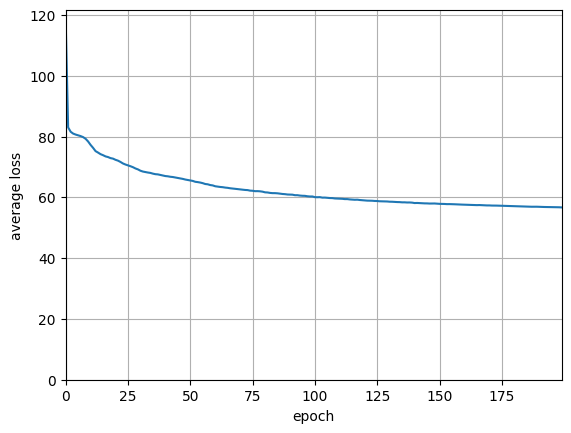

In [41]:
############################## Q 5.5 ##############################
def train_vae(
    max_iters: int = 200,
    batch_size: int = 36,
    learning_rate: float = 3e-5,
    lr_rate: int = 20,
    beta: float = 0.5,
) -> dict[str, Any]:
    """Train a variational autoencoder on the NIST36 dataset."""
    global rng
    rng = np.random.default_rng(seed=0)  # reset rng for reproducibility

    batches = get_random_batches(train_x, np.ones((train_x.shape[0], 1)), batch_size)
    params = initialize_vae()

    losses = []
    for itr in range(max_iters):
        total_loss = 0

        for xb, _ in batches:
            # Forward pass through the VAE
            # The code should compute the `out`, `mu`, and `logvar` and the reconstruction loss
            hidden_encoder = forward(xb, params, "encoder", relu)
            mu = forward(hidden_encoder, params, "mu", linear)
            logvar = forward(hidden_encoder, params, "logvar", linear)
            z, epsilon = reparameterize(mu, logvar)
            hidden_decoder = forward(z, params, "decoder", relu)
            output = forward(hidden_decoder, params, "output", sigmoid)

            mu = forward(hidden_encoder, params, "mu", linear)
            logvar = forward(hidden_encoder, params, "logvar", linear)

            # Loss calculation
            rec = np.sum((output - xb) ** 2)
            kl = kl_divergence(mu, logvar)
            loss = rec + beta * kl
            total_loss += loss

            # Backward pass
            delta = 2 * (output - xb)
            delta = backward(delta, params, "output", sigmoid_deriv)
            delta_z = backward(delta, params, "decoder", relu_deriv)

            delta_mu = delta_z + beta * mu
            delta_logvar = delta_z * 0.5 * np.exp(0.5 * logvar) * epsilon + beta * 0.5 * (np.exp(logvar) - 1)

            delta_encoder_mu = backward(delta_mu, params, "mu", linear_deriv)
            delta_encoder_logvar = backward(delta_logvar, params, "logvar", linear_deriv)
            delta_encoder = delta_encoder_mu + delta_encoder_logvar
            backward(delta_encoder, params, "encoder", relu_deriv)

            # Update parameters
            for name in ["encoder","mu","logvar","decoder","output"]:
                params[f"W{name}"] -= learning_rate * params[f"grad_W{name}"]
                params[f"b{name}"] -= learning_rate * params[f"grad_b{name}"]

        losses.append(total_loss / train_x.shape[0])
        if itr % 2 == 0:
            print(f"itr: {itr:02d} \t loss: {total_loss:.2f}")
        if itr % lr_rate == lr_rate - 1:
            learning_rate *= 0.9

    plot_curves({"training": losses}, "average loss")

    return params


params_vae = train_vae()

## Q5.6 (Extra Credit) (2 points) Generating Samples with VAE

Generate samples from the trained VAE by using the function implemented earlier. Include 9 generated samples in a $3 \times 3$ grid and compare to the samples generated earlier in Q5.1.

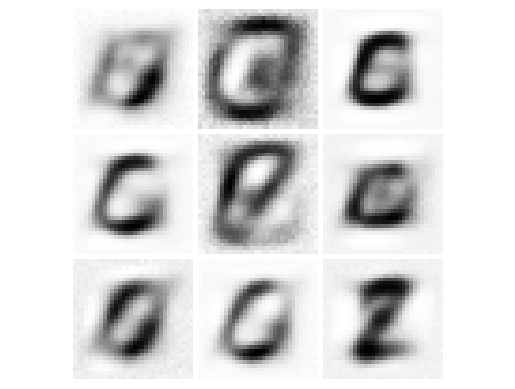

In [46]:
generated_samples_vae = []
z = rng.normal(size=(9, 32))
hidden_decoder = forward(z, params_vae, "decoder", relu)
output = forward(hidden_decoder, params_vae, "output", sigmoid)
generated_samples_vae = output.reshape((9, 32, 32))

# visualize the generated samples
show_image_grid(generated_samples_vae, nrows_ncols=(3, 3), cmap="gray")

Compare the generated samples with the samples generated by the autoencoder in Q5.1. What do you observe?

---

The samples is less noisy and with some contours compared with samples generated from Q5.1.

---

# Q6 (Extra Credit) Image-Text Representations with CLIP

In Q4, you trained an encoder to compress an image into a 32-dimension vector. This compressed **representation** contains information about the image's visual content, e.g., shapes and textures, allowing a decoder to reconstruct the original image from it. However, the representation does not (directly) contain any information about the image's textual description: Is it a picture of a dog? A tabby cat on a chair? A handwritten letter A? A representation that contains *both image and text information* would be useful in applications like image classification, captioning, and even text-to-image generation.

**CLIP (Contrastive Language-Image Pre-training)** is a method for learning such *joint image-text representations*. It trains two encoders at once—an image encoder and a text encoder—that map both pictures and words into a shared representation space, so that **an image and the text caption describing it have similar representations**.

To train a CLIP model, we use a dataset of (image, caption) pairs and a **contrastive** objective: for a batch of $B$ pairs, the model is asked to match each image to its own caption rather than to the other $B - 1$ captions, using **cosine similarity** between the image and text representations as the score:

$$\mathop{\text{sim}}(\mathbf{u}, \mathbf{v}) = \frac{\mathbf{u} \cdot \mathbf{v}}{\|\mathbf{u}\| \, \|\mathbf{v}\|} \in [-1, 1].$$

We have provided you with a pre-trained CLIP model; you do not need to train your own. You will use this model to perform **zero-shot classification**, creating an image classifier with no additional training needed!

Run the below code to download the pretrained CLIP weights and load the model.

In [52]:
############################## Q 6 setup ##############################
# Download the pretrained CLIP weights (~600 MB) and its tokenizer vocabulary.
# This only needs to run once per session.
CLIP_DIR = "/content/clip"
CLIP_REPO = "https://huggingface.co/laion/CLIP-ViT-B-32-laion2B-s34B-b79K/resolve/main"

if not os.path.exists(f"{CLIP_DIR}/model.safetensors"):
    os.makedirs(CLIP_DIR, exist_ok=True)
    for filename in ["model.safetensors", "vocab.json", "merges.txt"]:
        !wget -q --show-progress "{CLIP_REPO}/{filename}" -O "{CLIP_DIR}/{filename}"

%ls -lh /content/clip

total 579M
-rw-r--r-- 1 root root 513K Sep 17 21:14 merges.txt
-rw-r--r-- 1 root root 578M Sep 17 21:14 model.safetensors
-rw-r--r-- 1 root root 843K Sep 17 21:14 vocab.json


In [50]:
# ==================== PROVIDED CODE: a pure-numpy CLIP (ViT-B/32) ====================
# You do NOT need to modify anything in this cell. It is here so you can see that a
# real pretrained vision-language model is built from exactly the pieces you wrote in
# Q2: matrix multiplies, softmax, and elementwise nonlinearities (plus layer norm).
# Note that since the pretrained CLIP is trained on 224x224 images, we resize the NIST36 images passing them to the model.
import html
import json
import re
from functools import lru_cache

from scipy.special import erf
from skimage.transform import resize

CLIP_MEAN = np.array([0.48145466, 0.4578275, 0.40821073], dtype=np.float32)
CLIP_STD = np.array([0.26862954, 0.26130258, 0.27577711], dtype=np.float32)


def load_safetensors(path: str) -> dict[str, np.ndarray]:
    """Read a .safetensors file into a dict of numpy arrays."""
    with open(path, "rb") as f:
        header = json.loads(f.read(int(np.frombuffer(f.read(8), dtype="<u8")[0])))
        buf = f.read()
    dtypes = {"F32": "<f4", "F16": "<f2", "I64": "<i8"}
    out = {}
    for key, spec in header.items():
        if key == "__metadata__":
            continue
        start, end = spec["data_offsets"]
        arr = np.frombuffer(buf[start:end], dtype=dtypes[spec["dtype"]])
        out[key] = arr.reshape(spec["shape"]).astype(np.float32)
    return out


@lru_cache
def _bytes_to_unicode() -> dict[int, str]:
    bs = (
        list(range(ord("!"), ord("~") + 1))
        + list(range(ord("\xa1"), ord("\xac") + 1))
        + list(range(ord("\xae"), ord("\xff") + 1))
    )
    cs, n = bs[:], 0
    for b in range(256):
        if b not in bs:
            bs.append(b)
            cs.append(256 + n)
            n += 1
    return dict(zip(bs, [chr(c) for c in cs]))


class CLIPTokenizer:
    """CLIP's byte-pair-encoding tokenizer: text -> a sequence of integer token ids."""

    PATTERN = re.compile(
        r"""<\|startoftext\|>|<\|endoftext\|>|'s|'t|'re|'ve|'m|'ll|'d|[^\W\d_]+|\d|[^\s\w]+""",
        re.IGNORECASE,
    )

    def __init__(self, vocab_path: str, merges_path: str) -> None:
        with open(vocab_path) as f:
            self.encoder = json.load(f)
        with open(merges_path, encoding="utf-8") as f:
            merges = [tuple(line.split()) for line in f.read().split("\n")[1:]]
        self.bpe_ranks = {m: i for i, m in enumerate(m for m in merges if len(m) == 2)}
        self.byte_encoder = _bytes_to_unicode()
        self.cache: dict[str, str] = {}
        self.sot = self.encoder["<|startoftext|>"]
        self.eot = self.encoder["<|endoftext|>"]

    def _bpe(self, token: str) -> str:
        if token in self.cache:
            return self.cache[token]
        word = tuple(token[:-1]) + (token[-1] + "</w>",)
        while len(word) > 1:
            pairs = {(word[i], word[i + 1]) for i in range(len(word) - 1)}
            bigram = min(pairs, key=lambda p: self.bpe_ranks.get(p, np.inf))
            if bigram not in self.bpe_ranks:
                break
            merged, i = [], 0
            while i < len(word):
                if (word[i], word[i + 1 : i + 2]) == (bigram[0], (bigram[1],)):
                    merged.append(bigram[0] + bigram[1])
                    i += 2
                else:
                    merged.append(word[i])
                    i += 1
            word = tuple(merged)
        self.cache[token] = " ".join(word)
        return self.cache[token]

    def __call__(self, texts: list[str] | str, context_length: int = 77) -> np.ndarray:
        if isinstance(texts, str):
            texts = [texts]
        all_ids = []
        for text in texts:
            text = re.sub(r"\s+", " ", html.unescape(text).strip().lower())
            ids = [self.sot]
            for chunk in self.PATTERN.findall(text):
                chunk = "".join(self.byte_encoder[b] for b in chunk.encode("utf-8"))
                ids += [self.encoder[t] for t in self._bpe(chunk).split(" ")]
            ids += [self.eot]
            if len(ids) > context_length:
                # truncate, keeping the end-of-text token last
                ids = ids[: context_length - 1] + [self.eot]
            all_ids.append(ids)
        # Only pad out to the longest prompt: CLIP's text encoder is causal, so
        # trimming the unused tail positions does not change the result (and is faster).
        width = max(len(ids) for ids in all_ids)
        tokens = np.zeros((len(all_ids), width), dtype=np.int64)
        for i, ids in enumerate(all_ids):
            tokens[i, : len(ids)] = ids
        return tokens


def layer_norm(x: np.ndarray, weight: np.ndarray, bias: np.ndarray) -> np.ndarray:
    """Normalize each row to zero mean / unit variance, then rescale and shift."""
    x = (x - x.mean(-1, keepdims=True)) / np.sqrt(x.var(-1, keepdims=True) + 1e-5)
    return x * weight + bias


def gelu(x: np.ndarray) -> np.ndarray:
    """A smooth alternative to ReLU, used inside transformers."""
    return 0.5 * x * (1.0 + erf(x * 0.7071067811865476))  # 1/sqrt(2)


def batched_softmax(x: np.ndarray) -> np.ndarray:
    """Softmax over the last axis, the same function as Q2.2.2, on more axes."""
    e = np.exp(x - x.max(-1, keepdims=True))
    return e / e.sum(-1, keepdims=True)


def multi_head_attention(
    x: np.ndarray, p: dict[str, np.ndarray], prefix: str, n_heads: int, causal: bool
) -> np.ndarray:
    """Let every token look at the other tokens and pull in information from them."""
    n, seq_len, dim = x.shape
    head_dim = dim // n_heads

    def project(which: str) -> np.ndarray:
        out = (
            x @ p[prefix + which + "_proj.weight"].T + p[prefix + which + "_proj.bias"]
        )
        return out.reshape(n, seq_len, n_heads, head_dim).transpose(0, 2, 1, 3)

    q, k, v = project("q"), project("k"), project("v")
    scores = q @ k.transpose(0, 1, 3, 2) * float(head_dim) ** -0.5
    if causal:  # a text token may only attend to itself and the tokens before it
        scores += np.triu(np.full((seq_len, seq_len), -np.inf, dtype=np.float32), 1)
    attended = (
        (batched_softmax(scores) @ v).transpose(0, 2, 1, 3).reshape(n, seq_len, dim)
    )
    return attended @ p[prefix + "out_proj.weight"].T + p[prefix + "out_proj.bias"]


def transformer(
    x: np.ndarray,
    p: dict[str, np.ndarray],
    prefix: str,
    n_heads: int,
    causal: bool = False,
) -> np.ndarray:
    """Stack of 12 blocks, each one attention sublayer followed by a 2-layer MLP."""
    for i in range(12):
        q = f"{prefix}layers.{i}."
        h = layer_norm(x, p[q + "layer_norm1.weight"], p[q + "layer_norm1.bias"])
        x = x + multi_head_attention(h, p, q + "self_attn.", n_heads, causal)
        h = layer_norm(x, p[q + "layer_norm2.weight"], p[q + "layer_norm2.bias"])
        h = gelu(h @ p[q + "mlp.fc1.weight"].T + p[q + "mlp.fc1.bias"])
        x = x + h @ p[q + "mlp.fc2.weight"].T + p[q + "mlp.fc2.bias"]
    return x


class NumpyCLIP:
    """Pretrained CLIP ViT-B/32. Maps images and text into one shared 512-d space."""

    def __init__(self, weights_path: str, vocab_path: str, merges_path: str) -> None:
        self.p = load_safetensors(weights_path)
        self.tokenize = CLIPTokenizer(vocab_path, merges_path)

    @staticmethod
    def preprocess(images: np.ndarray) -> np.ndarray:
        """NIST36 rows of 1024 pixels -> the 224x224 RGB input CLIP expects."""
        images = np.atleast_2d(images).reshape(-1, 32, 32).transpose(0, 2, 1)
        # CLIP never saw 32x32 thumbnails in training, so give it something closer to
        # a photo of a character on paper: add a white margin, then upsample smoothly.
        images = np.pad(images, ((0, 0), (16, 16), (16, 16)), constant_values=1.0)
        images = np.stack(
            [
                resize(im, (224, 224), order=3, anti_aliasing=False).clip(0, 1)
                for im in images
            ]
        )
        rgb = np.repeat(images[:, None].astype(np.float32), 3, axis=1)
        return (rgb - CLIP_MEAN[None, :, None, None]) / CLIP_STD[None, :, None, None]

    def encode_image(self, images: np.ndarray, batch_size: int = 50) -> np.ndarray:
        """NIST36 images, [N, 1024] -> image embeddings, [N, 512]."""
        p = self.p
        patch = p["vision_model.embeddings.patch_embedding.weight"]
        patch_w = patch.reshape(patch.shape[0], -1).T  # 3*32*32 -> 768
        pixels = self.preprocess(images)
        embeddings = []
        for start in range(0, pixels.shape[0], batch_size):
            batch = pixels[start : start + batch_size]
            n = batch.shape[0]
            # Cut the image into a 7x7 grid of 32x32 patches and embed each one.
            patches = batch.reshape(n, 3, 7, 32, 7, 32).transpose(0, 2, 4, 1, 3, 5)
            h = patches.reshape(n, 49, 3 * 32 * 32) @ patch_w
            cls = np.broadcast_to(
                p["vision_model.embeddings.class_embedding"], (n, 1, 768)
            )
            h = np.concatenate([cls, h], axis=1)
            h = h + p["vision_model.embeddings.position_embedding.weight"]
            h = layer_norm(
                h,
                p["vision_model.pre_layrnorm.weight"],
                p["vision_model.pre_layrnorm.bias"],
            )
            h = transformer(h, p, "vision_model.encoder.", n_heads=12)
            # The class token summarizes the whole image.
            pooled = layer_norm(
                h[:, 0],
                p["vision_model.post_layernorm.weight"],
                p["vision_model.post_layernorm.bias"],
            )
            embeddings.append(pooled @ p["visual_projection.weight"].T)
        return np.concatenate(embeddings, axis=0)

    def encode_text(self, prompts: list[str] | str) -> np.ndarray:
        """Text prompts -> text embeddings, [N, 512], in the same space as the images."""
        p = self.p
        tokens = self.tokenize(prompts)
        h = p["text_model.embeddings.token_embedding.weight"][tokens]
        h = h + p["text_model.embeddings.position_embedding.weight"][: tokens.shape[1]]
        h = transformer(h, p, "text_model.encoder.", n_heads=8, causal=True)
        h = layer_norm(
            h,
            p["text_model.final_layer_norm.weight"],
            p["text_model.final_layer_norm.bias"],
        )
        # The end-of-text token summarizes the whole prompt.
        pooled = h[np.arange(tokens.shape[0]), tokens.argmax(-1)]
        return pooled @ p["text_projection.weight"].T

In [53]:
############################## Q 6 setup ##############################
# Load the model once (takes ~20 s, mostly reading the 600 MB weight file).
clip = NumpyCLIP(
    f"{CLIP_DIR}/model.safetensors", f"{CLIP_DIR}/vocab.json", f"{CLIP_DIR}/merges.txt"
)

# Sanity check that the download and the weight file parsed correctly.
print(f"loaded {len(clip.p)} weight tensors")

loaded 400 weight tensors


## Q6.1 Image-Text Similarity

### Q6.1.1 (Extra Credit) (2 points)

Fill in the `cosine_similarity(a, b)` function to compute the cosine similarity between every row of `a` and every row of `b`.

In [47]:
############################## Q 6.1.1 ##############################
def cosine_similarity(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    """
    Compute the cosine similarity between every row of a and every row of b.

    Args:
        a: numpy array of size [number of rows in a, number of dimensions]
        b: numpy array of size [number of rows in b, number of dimensions]

    Returns:
        A numpy array of size [number of rows in a, number of rows in b], whose
        entry [i, j] is the cosine similarity between the vectors a[i] and b[j].
    """
    similarity = np.array([])
    dot_product = a @ b.T
    norm_a = np.linalg.norm(a, axis=1, keepdims=True)
    norm_b = np.linalg.norm(b, axis=1, keepdims=True).T
    similarity = dot_product / (norm_a * norm_b)
    return similarity


def check_cosine_similarity() -> None:
    """
    Check cosine_similarity against a few values worked out by hand.

    A vector is perfectly similar to itself and to any positive rescaling of itself,
    orthogonal vectors score 0, and an opposite-pointing vector scores -1.
    """
    check_a = np.array([[1.0, 0.0, 0.0], [1.0, 1.0, 0.0]])
    check_b = np.array(
        [[2.0, 0.0, 0.0], [0.0, 3.0, 0.0], [1.0, 1.0, 0.0], [-1.0, 0.0, 0.0]]
    )
    r = np.sqrt(0.5)
    expected = np.array([[1.0, 0.0, r, -1.0], [r, r, 1.0, -r]])
    assert cosine_similarity(check_a, check_b).shape == (2, 4), "wrong output shape"
    assert np.allclose(cosine_similarity(check_a, check_b), expected), "wrong values"
    print("cosine_similarity looks correct")


check_cosine_similarity()

cosine_similarity looks correct


### Q6.1.2 (Extra Credit) (4 points)

Choose 3 images from the NIST training dataset, then make a list of at least 8 candidate text prompts. Try to vary the prompts along several axes: the bare character (`"A"`), a more detailed description (`"a handwritten letter A on white paper"`), an unrelated control (`"a photo of a golden retriever"`), and a deliberately wrong character. Encode the images and prompts using `clip.encode_image()` and `clip.encode_text()`, then score the encodings against each other using the similarity function you just wrote. Are the results what you expected? *Note that CLIP similarities are not calibrated probabilities. Look at how the prompts rank against each other for a fixed image, not at the absolute values.*

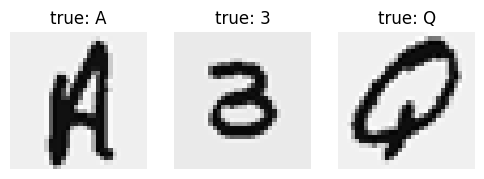


true character: A
   1. +0.3137  'the letter A'
   2. +0.2853  'a handwritten letter A on white paper'
   3. +0.2780  'A'
   4. +0.2606  'Q'
   5. +0.2308  '3'
   6. +0.2243  'a handwritten letter Q on white paper'
   7. +0.2225  'the letter Q'
   8. +0.2181  'the letter B'
   9. +0.2150  'a handwritten number 3 on white paper'
  10. +0.2005  'the number 3'
  11. +0.1749  'the number 8'
  12. +0.1135  'a photo of a golden retriever'

true character: 3
   1. +0.3194  'a handwritten number 3 on white paper'
   2. +0.3106  'the number 3'
   3. +0.2932  'the number 8'
   4. +0.2768  '3'
   5. +0.2657  'Q'
   6. +0.2611  'the letter B'
   7. +0.2549  'A'
   8. +0.2334  'the letter Q'
   9. +0.2184  'a handwritten letter Q on white paper'
  10. +0.2164  'the letter A'
  11. +0.2015  'a handwritten letter A on white paper'
  12. +0.1068  'a photo of a golden retriever'

true character: Q
   1. +0.2820  'Q'
   2. +0.2617  'a handwritten letter Q on white paper'
   3. +0.2529  'A'
   4. +0.246

In [54]:
############################## Q 6.1.2 ##############################
def show_labeled_images(images: np.ndarray, labels: list[str]) -> None:
    """Display a row of NIST36 images, each titled with its true label."""
    _, axes = plt.subplots(1, len(labels), figsize=(2 * len(labels), 2.4))
    for ax, image, label in zip(np.atleast_1d(axes), images, labels):
        ax.imshow(image.reshape(32, 32).T, cmap="gray")
        ax.set_title(f"true: {label}")
        ax.set_axis_off()
    plt.show()


def compare_images_to_prompts(indices: list[int], prompts: list[str]) -> None:
    """Display the chosen training images, then rank the prompts against each one."""
    # display the images you chose, with their true labels
    images = train_x[indices]
    labels = [CLASSES[i] for i in train_y[indices].argmax(1)]
    show_labeled_images(images, labels)

    # Embed both sides with clip.encode_image and clip.encode_text, then use your
    # cosine_similarity to score every image against every prompt: similarity[i, j]
    # should be the similarity between images[i] and prompts[j].
    similarity = np.array([])
    image_embeddings = clip.encode_image(images)
    text_embeddings = clip.encode_text(prompts)
    similarity = cosine_similarity(image_embeddings, text_embeddings)

    # print a ranked table of prompts for each image
    for label, row in zip(labels, similarity):
        print(f"\ntrue character: {label}")
        for rank, j in enumerate(np.argsort(-row)):
            print(f"  {rank + 1:2d}. {row[j]:+.4f}  {prompts[j]!r}")


# Choose a few training images, and write your own candidate prompts.
chosen_labels = ["A", "3", "Q"]

chosen_indices = [np.flatnonzero(train_y.argmax(1) == CLASSES.index(label))[0] for label in chosen_labels]

candidate_prompts = [
    "A",
    "the letter A",
    "a handwritten letter A on white paper",
    "3",
    "the number 3",
    "a handwritten number 3 on white paper",
    "Q",
    "the letter Q",
    "a handwritten letter Q on white paper",
    "the letter B",
    "the number 8",
    "a photo of a golden retriever",
]

compare_images_to_prompts(chosen_indices, candidate_prompts)

---

The results are as expected.

---

## Q6.2 Zero-shot Classification

### Q6.2 (Extra Credit) (4 points)

Now let's turn CLIP into an image classifier: build one prompt per output class, encode all 36 of them, and predict the class whose prompt has the highest cosine similarity with the image. Run this classifier on the given NIST validation subset. With a well-chosen prompt, you should get an accuracy of above 60% without any classification-specific training.

In [55]:
############################## Q 6.2 ##############################
def prompt_for(character: str) -> str:
    """Build the text prompt used to represent one NIST36 class."""
    if character.isdigit():
        return f"a handwritten number {character} on white paper"
    else:
        return f"a handwritten letter {character} on white paper"
    return character


def run_zero_shot_classification() -> None:
    """Classify a class-balanced sample of the validation set using CLIP."""
    # take a class-balanced sample of the validation set to keep the runtime reasonable
    sample_rng = np.random.default_rng(seed=0)
    valid_labels = valid_y.argmax(1)
    sample = np.concatenate(
        [
            sample_rng.choice(np.flatnonzero(valid_labels == c), 5, replace=False)
            for c in range(len(CLASSES))
        ]
    )
    sampled_images = valid_x[sample]

    # Embed one prompt per class and the sampled images, then predict each image's class.
    # predictions[i] should be the predicted class index for the image valid_x[sample][i].
    # Encoding the 180 sampled images takes ~10 s.
    predictions = np.array([])
    prompts = [prompt_for(character) for character in CLASSES]
    text_embeddings = clip.encode_text(prompts)

    # Embed validation images
    image_embeddings = clip.encode_image(sampled_images)

    # Compare every image against all 36 prompts
    similarity = cosine_similarity(image_embeddings, text_embeddings)

    # Choose the prompt/class with maximum similarity
    predictions = np.argmax(similarity, axis=1)

    truth = valid_labels[sample]
    print(
        f"zero-shot accuracy: {float(np.mean(predictions == truth)) * 100:.1f}%  (chance is 2.8%)"
    )


run_zero_shot_classification()

zero-shot accuracy: 73.3%  (chance is 2.8%)


---

The zero-shot accuracy is 73.3%.

---

# Q7 AI Assistance

1. Did you use any artificial intelligence assistance in solving any part of this assignment? (Yes/No)

**Answer here: Yes**

2. If you answered "Yes", give full details (e.g. "I used Claude to identify and debug errors in my code implementation for Question 2").

**Answer here: ChatGPT is used to refine the quality of the code and debug.**